<a href="https://colab.research.google.com/github/imguru-mooc/AI_CAMPUS/blob/main/QP-day6/QP_Day6_lecture.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a> <a href="https://kaggle.com/kernels/welcome?src=https://github.com/imguru-mooc/AI_CAMPUS/blob/main/QP-day6/QP_Day6_lecture.ipynb" target="_blank"><img src="https://kaggle.com/static/images/open-in-kaggle.svg" alt="Open In Kaggle"/></a>

# Quantization·Pruning Day 6 — 통합 경량화 파이프라인

**온디바이스 AI · Quantization·Pruning 6/6 · 11/23(월)** · Google Colab 또는 Kaggle · **GPU (T4) 권장** · PyTorch · torch-pruning · ModelOpt · TensorRT 10

Day 5 의 50% 가지치기 모델은 fine-tuning 뒤에도 정확도 0.72 로 FP32 (0.846) 와 12%p 차이가 남았습니다. 오늘은

1. 원본을 **선생님**, 가지치기한 모델을 **학생**으로 두는 **지식 증류 (Knowledge Distillation, KD)** 로 이 차이를 줄이고,
2. **Prune → KD → INT8 → TensorRT** 순서의 파이프라인을 완성한 뒤 (순서를 바꾸면 무슨 일이 생기는지도 확인),
3. Day 3 의 **YOLOv8n INT8** 을 OT Day 5 의 **침입 감지 파이프라인**에 넣어 엔진만 교체하고,
4. 엔진별 **이벤트 일치율 · 프레임 시간** 을 비교해 `qp_baseline.csv` 와 **경량화 결정표**로 배포안을 고릅니다.
5. 마지막 교시는 내일 **파트2 평가** 를 대비한 예제 2문항 (쉬움 · 중간) 미니 프로젝트입니다.

> **KD** → **Prune + KD** → **순서** → **탐지 모델 INT8** → **파이프라인 교체** → **결과 비교** → **배포 판단** → **평가 대비**

오늘의 목표

1. soft target · temperature 를 설명하고 KD loss = α·CE + (1 − α)·T²·KL 을 구현할 수 있다.
2. 가지치기한 모델을 원본을 선생님으로 학습시켜 일반 fine-tuning 과 **같은 예산**으로 비교할 수 있다.
3. Prune → KD → INT8 순서의 이유를 설명하고, 순서를 바꾸면 생기는 문제를 오류로 확인할 수 있다.
4. YOLOv8n 을 **배포 환경의 영상**으로 보정해 INT8 · INT8-mixed 모델을 만들고 침입 감지 파이프라인의 엔진만 교체할 수 있다.
5. 프레임 시간을 읽기 · 전처리 · 추론 · 후처리로 나누고, 엔진별 이벤트 일치율을 FP16 기준으로 잴 수 있다.
6. 최종 `qp_baseline.csv` 와 디바이스별 경량화 결정표를 만들 수 있다.

| 교시 | 시간 | 주제 |
|---|---|---|
| 1 | 09:00–09:50 | Knowledge Distillation — soft target · temperature · KD loss |
| 2 | 10:00–10:50 | Pruning + KD — 가지치기 모델을 선생님에게 배우게 하기 |
| 3 | 11:00–11:50 | 순서의 문제 — Prune → KD → INT8 · compress.py |
| 4 | 13:00–13:50 | 탐지 모델 경량화 — YOLOv8n INT8 · INT8-mixed 준비 |
| 5 | 14:00–14:50 | 침입 감지 파이프라인 교체 — 프레임 시간 4단계 |
| 6 | 15:00–15:50 | 결과 비교 — 이벤트 일치율 · 병목의 이동 |
| 7 | 16:00–16:50 | 배포 판단 — 최종 qp_baseline · 경량화 결정표 |
| 8 | 17:00–17:50 | 미니 프로젝트 — 평가 대비 예제 2문항 · 채점 |

**노트북 사용법**

1. 아래 **0. 실행 환경 준비**대로 내 사본을 만들고 **GPU (T4)** 런타임으로 바꿉니다. 오늘도 **학습 (KD)** 이 있습니다 — GPU 에서는 3 epoch 가 십여 초, CPU 에서는 40 ~ 70초씩 걸립니다 (CPU 로도 끝까지 됩니다).
2. **✍️ 직접 구현** 셀은 `# TODO` 를 직접 작성합니다 (교시당 2문제). 확인 셀이 `✅` 를 출력하면 정답입니다. 막히면 **💡 힌트** 셀 (실행할 때마다 하나씩 더).
3. **🔒 정답 보기** 셀은 **실습마다 다른 잠금 코드**로 잠겨 있습니다. 정답을 연 기록은 8교시 채점 셀에 표시됩니다.
4. **▶ 예제 (제공 코드)** 셀은 직접 구현이 아닙니다 — 그대로 실행하고 출력 · 해설을 읽습니다. 뒤 교시가 이 셀의 함수 · 변수를 쓰므로 **건너뛰지 말고 실행**하세요.
5. **학습 결과 · 시간은 GPU · 세션마다 조금씩 다릅니다.** 교안의 숫자는 강사 실측 **예시**입니다.
6. 8교시 미니 프로젝트는 끝에 있습니다 (정답 셀 없음). 채점 셀 결과가 보이는 상태로 제출합니다.
7. 수업이 끝나면 **Day 6 복습 퀴즈**(HTML)를 풀고 제출합니다.

## 0. 실행 환경 준비 — Colab 또는 Kaggle

| 단계 | Google Colab | Kaggle |
|---|---|---|
| 열기 | 맨 위 **Open in Colab** 배지 | 맨 위 **Open in Kaggle** 배지 (또는 *File → Import Notebook* 에서 GitHub 주소 붙여넣기) |
| 내 사본 | *파일 → Drive에 사본 저장* | 열면 내 계정의 노트북으로 만들어짐 · 작업 후 **Save Version** |
| **GPU** | *런타임 → 런타임 유형 변경 → T4 GPU* | 오른쪽 패널 *Session options → Accelerator → **GPU T4 x2*** |
| 인터넷 | 기본으로 켜져 있음 | *Session options → **Internet On*** (처음 한 번 **전화번호 인증**) — torch-pruning · ModelOpt · TensorRT 설치에 필요 |
| 생성형 AI | 이 노트북은 **생성형 AI 기능이 숨겨진 상태**로 배포됩니다. **다시 켜지 마세요** — 제출 파일에서 이 설정을 확인합니다. *도구 → 설정 → AI 지원* 의 **AI 기반 인라인 완성 표시** 도 꺼 두세요 | 노트북 안에 AI 자동 완성 없음 |
| 숨김 셀 | 🔒 · 🖼 · 💡 셀은 코드가 접혀 있음 | 코드가 보이지만 그대로 실행하면 됨 |

> 아래 **환경 셀**을 실행하면 `실행 환경`, GPU, `torch-pruning` · `ModelOpt` · `tensorrt` 버전이 출력됩니다. 처음에는 설치에 2~3분 걸립니다.

### 📚 오늘의 온라인 자료

| 자료 | 링크 |
|---|---|
| 🎬 애니메이션 (시뮬레이션 8개) | [https://imguru-mooc.github.io/AI_CAMPUS/QP-day6/animation.html](https://imguru-mooc.github.io/AI_CAMPUS/QP-day6/animation.html) |
| 📝 Day 6 복습 퀴즈 (수업이 끝난 뒤, 24문항) | [https://imguru-mooc.github.io/AI_CAMPUS/QP-day6/review_quiz.html](https://imguru-mooc.github.io/AI_CAMPUS/QP-day6/review_quiz.html) |
| 🖥 슬라이드 (PDF) | [https://imguru-mooc.github.io/AI_CAMPUS/QP-day6/QP_Day6.pdf](https://imguru-mooc.github.io/AI_CAMPUS/QP-day6/QP_Day6.pdf) |

**오늘의 데이터 · 모델** — Day 2 ~ 5 의 **ResNet-20** (`resnet20_cifar10.pt`, FP32 0.846) 과 CIFAR-10 학습용 10,000장 · 보정용 500장 · 평가용 2,000장, OT Day 5 · QP Day 3 의 **YOLOv8n** (`yolov8n.onnx`) 과 침입 감지 영상 **`people.mp4`** (768 × 576 · 10 FPS · 795 프레임). 모두 노트북이 자동으로 내려받습니다.

> 커리큘럼 초안의 "ResNet18 → 소형 CNN" 대신 **원본 ResNet-20 (선생님) → 50% 가지치기한 ResNet-20 (학생)** 으로 KD 를 합니다. Day 2 ~ 5 와 같은 모델이라 `qp_baseline.csv` 한 표에서 양자화 · 가지치기 · KD 를 바로 비교할 수 있습니다.

In [ ]:
# ▶ 환경 셀 — 런타임이 끊기면 이 셀부터 다시 실행하세요
import os, sys, re, glob, json, copy, time, shutil, urllib.request, warnings, inspect, contextlib, io, importlib.util, subprocess, csv
from collections import Counter

# ── 실행 환경 감지 (Colab · Kaggle · 내 PC) ──
try:
    import google.colab  # noqa: F401
    PLATFORM = "Colab"
except ImportError:
    PLATFORM = "Kaggle" if ("KAGGLE_KERNEL_RUN_TYPE" in os.environ or os.path.isdir("/kaggle/working")) else "Local"
if PLATFORM == "Kaggle":
    os.chdir("/kaggle/working")

def _online(url="https://raw.githubusercontent.com", timeout=5):
    try:
        urllib.request.urlopen(url, timeout=timeout); return True
    except Exception:
        return False
ONLINE = _online()

import torch, torch.nn as nn, torch.nn.functional as F
GPU_OK = torch.cuda.is_available()

# ── 설치 (없을 때만): onnx · onnxruntime · torch-pruning · ModelOpt, GPU 이면 TensorRT 10 ──
_need = [p for p in ["onnx", "onnxruntime"] if importlib.util.find_spec(p) is None]
if importlib.util.find_spec("torch_pruning") is None:
    _need.append("torch-pruning==1.6.0")
if importlib.util.find_spec("modelopt") is None:
    _need.append("nvidia-modelopt==0.48.0")
if GPU_OK and importlib.util.find_spec("tensorrt") is None:
    _need.append("tensorrt-cu12==10.16.1.11")
if _need:
    print("설치:", _need, "— 처음 한 번 2~3분")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_need], check=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import onnx, onnxruntime as ort
from onnx import numpy_helper
from IPython.display import display, HTML
from onnxruntime.quantization import quantize_static, QuantFormat, QuantType, CalibrationDataReader
from onnxruntime.quantization.shape_inference import quant_pre_process
with contextlib.redirect_stderr(io.StringIO()):
    import modelopt, modelopt.torch.quantization as mtq
import torch.nn.utils.prune as prune
import torch_pruning as tp
import gzip
try:
    import tensorrt as trt
    TRT_OK = GPU_OK
except ImportError:
    trt, TRT_OK = None, False

warnings.filterwarnings("ignore")
np.set_printoptions(precision=4, suppress=True)
DEV = "cuda" if GPU_OK else "cpu"
pd.set_option("display.width", 160)
torch.manual_seed(0); np.random.seed(0)
BASE = "https://imguru-mooc.github.io/AI_CAMPUS/QP-day6"
RAW = "https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day6"
EXPORT_KW = {"dynamo": False} if "dynamo" in inspect.signature(torch.onnx.export).parameters else {}
CPU = ["CPUExecutionProvider"]
BACKEND = "TensorRT" if TRT_OK else "ORT CPU"

print(f"실행 환경: {PLATFORM} | 작업 폴더: {os.getcwd()} | 인터넷: {'연결됨' if ONLINE else '끊김'} | GPU: {torch.cuda.get_device_name(0) if GPU_OK else '없음'}")
print(f"PyTorch {torch.__version__} | torch-pruning {tp.__version__} | ModelOpt {modelopt.__version__} | onnx {onnx.__version__} | onnxruntime {ort.__version__} | TensorRT {trt.__version__ if trt else '없음'}")
if not TRT_OK:
    print("⚠️ GPU / TensorRT 없음 — 학습은 CPU 로 (3 epoch 에 약 40초씩), 엔진 셀은 ONNX Runtime CPU 로 대신 돌립니다 (4 ~ 6교시 영상은 뒤쪽 315프레임만).")

def fetch(name):
    """data/<name> 이 없으면 강의 자료 서버(GitHub Pages → GitHub 원본 순)에서 내려받는다"""
    path = os.path.join("data", name)
    if not os.path.exists(path):
        os.makedirs("data", exist_ok=True)
        for url in [f"{BASE}/data/{name}", f"{RAW}/data/{name}"]:
            try:
                urllib.request.urlretrieve(url, path)
                break
            except Exception as e:
                if os.path.exists(path): os.remove(path)
                print("내려받기 실패:", url, "→", e)
        else:
            raise FileNotFoundError(f"{name} 을 내려받지 못했습니다. 인터넷 연결을 확인하거나 강사에게 받은 파일을 data 폴더에 올리세요.")
    return path

@contextlib.contextmanager
def quiet():
    """도구의 긴 로그를 숨긴다"""
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        yield

def size_kb(path):
    return os.path.getsize(path) / 1024

def make_session(path, threads=1):
    so = ort.SessionOptions(); so.intra_op_num_threads = threads
    return ort.InferenceSession(path, so, providers=CPU)

def bench_fn(fn, n=100, warm=10):
    # fn() 을 warm 번 실행한 뒤 n 번 재서 ms 통계
    for _ in range(warm):
        fn()
    t = []
    for _ in range(n):
        t0 = time.perf_counter(); fn(); t.append((time.perf_counter() - t0) * 1000)
    t = np.array(t)
    return {"mean": float(t.mean()), "p95": float(np.percentile(t, 95)), "fps": float(1000 / t.mean())}

# ── TensorRT (GPU 일 때만) — OT Day 5 의 TRTInfer 그대로 ──
if TRT_OK:
    LOGGER = trt.Logger(trt.Logger.WARNING)
    RUNTIME = trt.Runtime(LOGGER)

    class TRTInfer:
        def __init__(self, engine_path):
            self.engine = RUNTIME.deserialize_cuda_engine(open(engine_path, "rb").read())
            self.context = self.engine.create_execution_context()
            names = [self.engine.get_tensor_name(i) for i in range(self.engine.num_io_tensors)]
            self.inputs = [n for n in names if self.engine.get_tensor_mode(n) == trt.TensorIOMode.INPUT]
            self.outputs = [n for n in names if self.engine.get_tensor_mode(n) == trt.TensorIOMode.OUTPUT]
            self.buf = {n: torch.empty(tuple(self.engine.get_tensor_shape(n)), dtype=torch.float32, device="cuda") for n in names}
            for n in names:
                self.context.set_tensor_address(n, self.buf[n].data_ptr())
            self.input_shape = tuple(self.engine.get_tensor_shape(self.inputs[0]))

        def __call__(self, x):
            self.buf[self.inputs[0]].copy_(torch.from_numpy(np.ascontiguousarray(x, dtype=np.float32)))
            self.context.execute_async_v3(torch.cuda.current_stream().cuda_stream)
            torch.cuda.synchronize()
            return self.buf[self.outputs[0]].cpu().numpy()

        def __repr__(self):
            return f"TRTInfer(in={self.inputs} {self.input_shape}, out={self.outputs})"

    def build_engine(onnx_path, engine_path, fp16=False, int8=False):      # Day 3 실습 4-2
        builder = trt.Builder(LOGGER)
        network = builder.create_network(0)
        parser = trt.OnnxParser(network, LOGGER)
        if not parser.parse_from_file(onnx_path):
            raise RuntimeError("\n".join(str(parser.get_error(i)) for i in range(parser.num_errors)))
        config = builder.create_builder_config()
        config.set_memory_pool_limit(trt.MemoryPoolType.WORKSPACE, 1 << 30)
        if fp16:
            config.set_flag(trt.BuilderFlag.FP16)
        if int8:
            config.set_flag(trt.BuilderFlag.INT8)
        blob = builder.build_serialized_network(network, config)
        if blob is None:
            raise RuntimeError("빌드 실패 — 위 로그를 확인하세요")
        with open(engine_path, "wb") as f:
            f.write(blob)
        return engine_path

def build_once(onnx_path, engine_path, fp16=False, int8=False):
    """엔진이 이미 있으면 다시 만들지 않는다 (Day 3)"""
    if not os.path.exists(engine_path):
        t0 = time.time(); build_engine(onnx_path, engine_path, fp16=fp16, int8=int8)
        print(f"빌드 {engine_path} — {time.time() - t0:.0f} 초")
    return engine_path

import hashlib, base64, datetime
_HINT_N = {}
def show_hint(no, blob):
    # 💡 실행할 때마다 힌트를 하나씩 더 보여 준다
    hints = base64.b64decode(blob).decode("utf-8").split("\x1e")
    k = min(_HINT_N.get(no, 0) + 1, len(hints)); _HINT_N[no] = k
    for i in range(k):
        print(f"💡 힌트 {i + 1}/{len(hints)} — {hints[i]}")
    print("(다시 실행하면 다음 힌트)" if k < len(hints) else "(힌트를 모두 봤습니다 — 이제 직접 구현해 보세요)")

def show_answer(no, blob):
    # 🔒 잠금된 정답 보기 — 강사가 알려 준 '실습별' 잠금 코드가 있어야 열린다
    raw = base64.b64decode(blob); tag, body = raw[:8], raw[8:]
    for _ in range(2):
        code = input(f"🔒 실습 {no} 잠금 코드: ").strip().upper()
        ks, i = b"", 0
        while len(ks) < len(body):
            ks += hashlib.sha256(f"{code}|qp-day6|{no}|{i}".encode()).digest(); i += 1
        plain = bytes(a ^ b for a, b in zip(body, ks))
        if hashlib.sha256(plain).digest()[:8] == tag:
            with open(".qp_answer_log", "a") as f:
                f.write(f"{no}\t{datetime.datetime.now():%H:%M}\n")
            print(plain.decode("utf-8")); return
        if not code: break
    print("❌ 잠금 코드가 맞지 않습니다. 강사가 이 실습의 코드를 공개하면 다시 실행하세요.")

In [ ]:
# ▶ 데이터 · 모델 셀 (1) — CIFAR-10 · ResNet-20 · Day 2 ~ 5 에서 만든 함수
MEAN = np.array((0.4914, 0.4822, 0.4465), np.float32)
STD = np.array((0.2470, 0.2435, 0.2616), np.float32)
ev, tr, cal = np.load(fetch("cifar_eval.npz")), np.load(fetch("cifar_train10k.npz")), np.load(fetch("cifar_calib.npz"))

def preprocess(images):
    x = images.astype(np.float32) / 255.0
    return ((x - MEAN) / STD).transpose(0, 3, 1, 2).copy()

X_ev, y_ev, X_cal = preprocess(ev["images"]), ev["labels"], preprocess(cal["images"])
if "images" in tr.files:
    Xtr_u8 = tr["images"]
else:                                              # GitHub 25 MB 제한 때문에 10,000장을 100 × 100 모자이크 PNG (무손실) 로 저장한 형식
    _m = cv2.imdecode(tr["images_png"], cv2.IMREAD_COLOR)[..., ::-1]
    Xtr_u8 = np.ascontiguousarray(_m.reshape(100, 32, 100, 32, 3).transpose(0, 2, 1, 3, 4).reshape(-1, 32, 32, 3))
ytr = tr["labels"]

class BasicBlock(nn.Module):                      # VB Day 2 · QP Day 2 ~ 4 와 같은 구조
    def __init__(self, cin, cout, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride=stride, padding=1, bias=False); self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, stride=1, padding=1, bias=False); self.bn2 = nn.BatchNorm2d(cout)
        self.shortcut = (nn.Sequential(nn.Conv2d(cin, cout, 1, stride=stride, bias=False), nn.BatchNorm2d(cout))
                         if stride != 1 or cin != cout else nn.Identity())

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.shortcut(x))

class ResNet(nn.Module):
    def __init__(self, n=3, n_cls=10):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 16, 3, padding=1, bias=False), nn.BatchNorm2d(16), nn.ReLU(inplace=True))
        self.layer1 = nn.Sequential(*[BasicBlock(16, 16) for _ in range(n)])
        self.layer2 = nn.Sequential(BasicBlock(16, 32, 2), *[BasicBlock(32, 32) for _ in range(n - 1)])
        self.layer3 = nn.Sequential(BasicBlock(32, 64, 2), *[BasicBlock(64, 64) for _ in range(n - 1)])
        self.pool = nn.AdaptiveAvgPool2d(1); self.fc = nn.Linear(64, n_cls)

    def forward(self, x):
        x = self.layer3(self.layer2(self.layer1(self.stem(x))))
        return self.fc(self.pool(x).flatten(1))

def load_rn20():
    m = ResNet(); m.load_state_dict(torch.load(fetch("resnet20_cifar10.pt"), map_location="cpu")); return m.eval()

def acc_torch(model, X=X_ev, y=y_ev, bs=500):
    model.eval(); dev = next(model.parameters()).device; preds = []
    with torch.no_grad():
        for i in range(0, len(X), bs):
            preds.append(model(torch.from_numpy(X[i:i + bs]).to(dev)).argmax(1).cpu().numpy())
    return float((np.concatenate(preds) == y).mean())

def batches(bs=128, seed=0):
    # 학습용 10,000장을 섞어 좌우 뒤집기 · 4픽셀 이동 증강 후 (x, y) 텐서로 (Day 4 와 같음)
    rng = np.random.default_rng(seed); idx = rng.permutation(len(Xtr_u8))
    for i in range(0, len(idx), bs):
        b = Xtr_u8[idx[i:i + bs]]
        b = np.where(rng.random(len(b))[:, None, None, None] < 0.5, b[:, :, ::-1], b)
        pad = np.pad(b, ((0, 0), (4, 4), (4, 4), (0, 0)), mode="reflect"); dx, dy = rng.integers(0, 9, 2)
        yield torch.from_numpy(preprocess(pad[:, dy:dy + 32, dx:dx + 32])).to(DEV), torch.from_numpy(ytr[idx[i:i + bs]]).to(DEV)

def convs(model):
    # 가지치기 대상 — Conv2d · Linear 의 (이름, 모듈) 목록
    return [(n, m) for n, m in model.named_modules() if isinstance(m, (nn.Conv2d, nn.Linear))]

def n_params(model):
    return sum(p.numel() for p in model.parameters())

def latency_torch(model, n=200, warm=20):
    # PyTorch CPU · 배치 1 평균 지연 (ms)
    model = model.cpu().eval(); x = torch.from_numpy(X_ev[:1])
    with torch.no_grad():
        return bench_fn(lambda: model(x), n=n, warm=warm)["mean"]

def export_b1(model, path):
    # 배치 1 고정 ONNX 로 내보내기 (TensorRT 엔진용) — 모델은 CPU 로 옮겨서
    model = model.cpu().eval()
    torch.onnx.export(model, torch.zeros(1, 3, 32, 32), path, input_names=["input"], output_names=["logits"], opset_version=17, **EXPORT_KW)
    return path

def onnx_acc(path, X=X_ev, y=y_ev):
    s = make_session(path, 0)
    return float(np.mean([s.run(None, {"input": X[i:i + 1]})[0].argmax() == y[i] for i in range(len(X))]))

def forward_loop(model):
    # 보정용 500장을 100장씩 흘린다 (ModelOpt 의 calibration loop — Day 4)
    dev = next(model.parameters()).device
    with torch.no_grad():
        for i in range(0, len(X_cal), 100):
            model(torch.from_numpy(X_cal[i:i + 100]).to(dev))

def const_values(graph):
    d = {i.name: numpy_helper.to_array(i) for i in graph.initializer}
    for n in graph.node:
        if n.op_type == "Constant":
            for a in n.attribute:
                if a.name == "value":
                    d[n.output[0]] = numpy_helper.to_array(a.t)
    return d

def trt_check(path):                               # Day 3 예제 4-A — TensorRT 가 받는 QDQ 인가 (S8 · zero_point 0)
    g = onnx.load(path).graph; c = const_values(g)
    qdq = [n for n in g.node if n.op_type in ("QuantizeLinear", "DequantizeLinear")]
    zps = [c[n.input[2]] for n in qdq if len(n.input) > 2 and n.input[2] in c]
    r = {"qdq": len(qdq), "uint8": sum(z.dtype == np.uint8 for z in zps), "nonzero_zp": sum(bool(np.any(z != 0)) for z in zps)}
    r["ok"] = r["qdq"] > 0 and r["uint8"] == 0 and r["nonzero_zp"] == 0
    return r

def make_trt_int8(src, dst, X=None):               # Day 3 실습 4-1 — ORT static PTQ (QDQ · S8 대칭 · 채널별), 배치 1 분류 모델용
    X = X_cal if X is None else X
    class _R(CalibrationDataReader):
        def __init__(self): self.it = iter([{"input": X[i:i + 1]} for i in range(len(X))])
        def get_next(self): return next(self.it, None)
    with quiet():
        quant_pre_process(src, dst + ".pre"); 
        quantize_static(dst + ".pre", dst, _R(), quant_format=QuantFormat.QDQ, per_channel=True, reduce_range=True,
                        activation_type=QuantType.QInt8, weight_type=QuantType.QInt8,
                        extra_options={"ActivationSymmetric": True, "WeightSymmetric": True, "QuantizeBias": False})
    os.remove(dst + ".pre")
    return dst

def make_pruner(model, ratio, steps=1):            # Day 5 실습 5-1
    return tp.pruner.MetaPruner(model, EX_IN, importance=tp.importance.MagnitudeImportance(p=1),
                                pruning_ratio=ratio, iterative_steps=steps, ignored_layers=[model.fc])

def prune_channels(model, ratio):                  # Day 5 실습 5-1 — 복사본의 채널을 ratio 만큼 자른다
    m = copy.deepcopy(model).cpu().eval()
    make_pruner(m, ratio).step()
    return m

def macs_m(model):
    return tp.utils.count_ops_and_params(copy.deepcopy(model).cpu().eval(), EX_IN)[0] / 1e6

def finetune(model, epochs=3, lr=1e-2, on_epoch=None):      # Day 5 실습 6-1 — 정답 (CE) 만 보고 학습
    model.to(DEV)
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=5e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs * (len(Xtr_u8) // 128 + 1))
    t0 = time.time()
    for ep in range(epochs):
        model.train()
        for xb, yb in batches(seed=ep):
            loss = F.cross_entropy(model(xb), yb)
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        model.eval()
        if on_epoch:
            on_epoch(ep, model)
    return time.time() - t0

def deploy_lat(onnx_path, int8=False, n=300):      # Day 4 · 5 — GPU 면 TensorRT 엔진 (FP16, QDQ 면 INT8 + FP16), 아니면 ORT CPU. 배치 1 평균 ms
    if TRT_OK:
        f = TRTInfer(build_once(onnx_path, onnx_path.replace(".onnx", "_int8.engine" if int8 else "_fp16.engine"), fp16=True, int8=int8))
    else:
        s = make_session(onnx_path); f = lambda x, s=s: s.run(None, {"input": x})[0]
    return bench_fn(lambda: f(X_ev[:1]), n=n, warm=30)["mean"]

CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
EX_IN = torch.randn(1, 3, 32, 32)               # torch-pruning 이 그래프를 따라갈 때 쓰는 예시 입력
EPOCHS = 3
rn20 = load_rn20()
FP32_ACC = acc_torch(rn20)
print(f"학습용 {Xtr_u8.shape} · 보정용 {X_cal.shape} · 평가용 {X_ev.shape} | 장치 {DEV} | ResNet-20 FP32 정확도 {FP32_ACC:.4f} · params {n_params(rn20):,}")

## 1교시 — Knowledge Distillation: soft target · temperature · KD loss

작은 모델 (**학생, student**) 을 정답 (hard label) 만으로 가르치지 않고, 큰 모델 (**선생님, teacher**) 의 **출력 분포**까지 따라 하게 합니다.

| 무엇 | hard label | soft target (선생님의 출력) |
|---|---|---|
| 한 장이 주는 정보 | "이 사진은 고양이" (1개) | "고양이 0.6 · 개 0.3 · 사슴 0.05 …" — **클래스 사이의 닮음** (dark knowledge) |
| 만드는 법 | 사람이 붙인 정답 | `softmax(teacher_logits / T)` |

**temperature T** — logits 를 T 로 나눈 뒤 softmax 를 합니다. T 가 클수록 분포가 평평해져 작은 확률 (2등 · 3등) 이 잘 보입니다.

**KD loss**

```
loss = α · CE(student, 정답)  +  (1 − α) · T² · KL( softmax(teacher / T)  ‖  softmax(student / T) )
```

| 기호 | 뜻 | 오늘의 값 |
|---|---|---|
| α | 정답 (CE) 의 비중 | 0.5 |
| T | temperature | 4 |
| T² | soft 항의 기울기가 1/T² 로 작아지는 것을 되돌리는 보정 | — |

> 선생님은 **학습하지 않습니다** (`torch.no_grad()` · `eval()`). 학생만 학습합니다. 추론할 때는 학생만 쓰므로 **배포 비용은 늘지 않습니다.**

> 🎬 **애니메이션** [D6-1 Knowledge Distillation](https://imguru-mooc.github.io/AI_CAMPUS/QP-day6/animation.html#d6-1)
> 애니메이션은 **이 교시의 노트북 순서 그대로**입니다 — 단계마다 먼저 **예측**을 고르고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

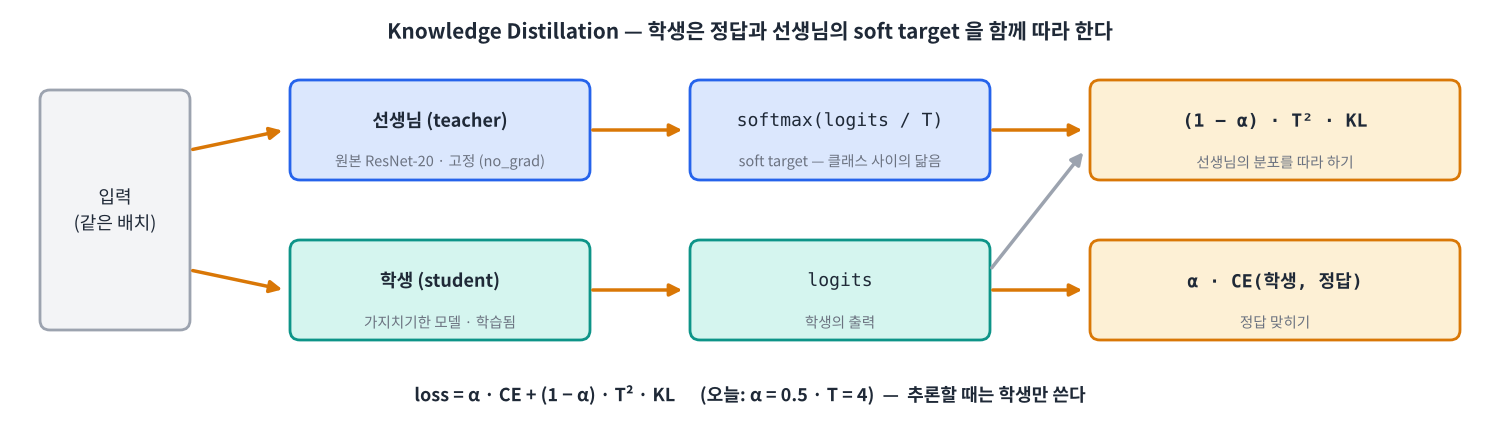

In [ ]:
#@title 🖼 그림 — Knowledge Distillation — 선생님의 soft target 과 정답을 함께 본다
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day6/img/f1_kd.png", embed=True, width=860))

**▶ 예제 1-A (제공 코드 — 실행만)** 선생님 (ResNet-20 FP32) 이 평가용 사진 한 장에 낸 logits 를 temperature **T = 1 · 4 · 10** 으로 softmax 한 결과입니다. 1등이 아닌 클래스의 확률이 T 에 따라 어떻게 바뀌는지 보세요.

> 이 셀은 **직접 구현이 아닙니다.** 그대로 실행하고, 출력과 아래 해설을 읽어 보세요.

In [ ]:
# ▶ 예제 1-A — 제공 코드 (그대로 실행)
IDX_DEMO = 0
with torch.no_grad():
    z_demo = rn20.cpu()(torch.from_numpy(X_ev[IDX_DEMO:IDX_DEMO + 1]))[0]
print("정답:", CLASSES[y_ev[IDX_DEMO]], "| logits 상위 3:", [(CLASSES[i], round(float(z_demo[i]), 2)) for i in z_demo.argsort(descending=True)[:3]])
demo_rows = []
for T in [1, 4, 10]:
    p = F.softmax(z_demo / T, 0); top = p.argsort(descending=True)[:3]
    demo_rows.append({"T": T, **{f"top{k + 1}": f"{CLASSES[i]} {p[i]:.3f}" for k, i in enumerate(top)}, "1등 외 합": round(float(1 - p.max()), 3)})
demo_df = pd.DataFrame(demo_rows)
display(demo_df)

In [ ]:
assert demo_df["1등 외 합"].is_monotonic_increasing
print("✅ T 가 커질수록 1등 외 클래스의 확률이 커진다 — 선생님이 '무엇과 헷갈리는지' 가 보인다")

> 💡 **예제 1-A 해설** — T = 1 에서는 1등 확률이 거의 1 이라 hard label 과 다를 바 없습니다. T 를 키우면 2등 · 3등 클래스의 확률이 드러납니다 — 이것이 학생에게 주는 추가 정보입니다. T 가 너무 크면 모든 클래스가 1/10 에 가까워져 정보가 다시 사라집니다. 보통 2 ~ 8 을 씁니다.

**✍️ 직접 구현 1-1** (1) logits `(N, C)` 를 temperature `T` 로 나눠 softmax 하는 `soft(logits, T=1.0)` 를 만드세요. (2) 선생님이 평가용 앞 500장에 낸 logits `t_logits` 로, T = 1 · 2 · 4 · 8 각각에서 **1등이 아닌 클래스에 준 확률의 평균** (1 − 최대 확률의 평균) 을 `dark = {T: 값}` 으로 구하세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 1-1 — 실행할 때마다 하나씩
show_hint("1-1", "YHNvZnRgOiBgRi5zb2Z0bWF4KGxvZ2l0cyAvIFQsIGRpbT0xKWAg4oCUIGRpbT0xIOydtCDtgbTrnpjsiqQg7LaVLh5gd2l0aCB0b3JjaC5ub19ncmFkKCk6IHRfbG9naXRzID0gcm4yMC5jcHUoKSh0b3JjaC5mcm9tX251bXB5KFhfZXZbOjUwMF0pKWAuHmBkYXJrID0ge1Q6IGZsb2F0KDEgLSBzb2Z0KHRfbG9naXRzLCBUKS5tYXgoMSkudmFsdWVzLm1lYW4oKSkgZm9yIFQgaW4gWzEsIDIsIDQsIDhdfWAu")

In [ ]:
# ✍️ 직접 구현 1-1 — soft target · temperature
def soft(logits, T=1.0):
    # TODO
    pass

t_logits = None   # TODO: 선생님 (rn20) 이 평가용 앞 500장에 낸 logits (no_grad)
dark = None       # TODO: {T: 1등 외 확률의 평균} for T in [1, 2, 4, 8]
print({k: round(v, 3) for k, v in dark.items()})

In [ ]:
assert torch.allclose(soft(t_logits, 3.0).sum(1), torch.ones(500), atol=1e-5) and torch.allclose(soft(t_logits), F.softmax(t_logits, 1))
assert set(dark) == {1, 2, 4, 8} and dark[1] < dark[2] < dark[4] < dark[8] < 0.9
print(f"✅ 1등 외 확률 — T=1 {dark[1]:.3f} → T=4 {dark[4]:.3f} → T=8 {dark[8]:.3f}")

In [ ]:
#@title 🔒 정답 보기 1-1 — 강사가 알려 준 실습 1-1 잠금 코드를 입력하세요
show_answer("1-1", (
    "Lh9e8qowFwW8jhGzVWpxMfXwUniLlnmE7R1YIfC8lWdJdO92Ek6Yb8vp+I60F0RZELShlk49uU66/2vaDX8NkEAt"
    "KQGSaVOkwOq5AUWlvPrUGumvoAGHYoHcFuNFson3dEwPfSW22LId+lh62y65oBklexouXTccZURWGU3fHbtLx7Is"
    "CDmk4O7K+BgQGsfcerhYN0gf9OAdO4+juoUaQt6fEMCEYyjFka5KRKId8vaoq7ewmobnFdmfCRzIs+V1Yl40MZrf"
    "DbuxYxxqBL8sJ/rFnaHBTp1F6W94+tganAU8asQFD+NV5QvHVZvHR6NiCjMDyz3+qpj9CbvHruuUurI5ooOEobgn"
    "VmkNxKQ13djLmrxFVtBF95qiai/bsIeOT4s2Sthr4zYu4bahi0djHSON1UMV4xINLuhev1I54DKT3URKzVYJN0QM"
    "IIffXrCJo1B1/z14V+cNlsk+tSFA04l7qDRotjSTN2NdqnhuqPZ6Htvd5b6E9nZG8wW3pCH1QCEBetSgJth8PjZw"
    "4piUcjo6oEdIgVIEsWt01ndV0xXoD1Fznpb24LBStBBe3R3ka6SlRUcB6JI//qUohzd6MPDeIffZBn8f/fksNRsh"
    "XIsr8UIQL5bakqEXJMcyN6n5MW9HTwNBvv+/o7rZQ1G1niIDk4hziS0WEA4MOyHR3P/VZnwJ+haHumEyHdwjYP1N"
    "yyOyQI1Jmh8opNiE2/9FVO6dn/ZLv3aq6CpbLhcuGSkLCC1qA3qS3RAXs36ILjIzQB+DtraLrP2KObXAoC7+ryrU"
    "aU5/GO2a5rVSeVZvXLra70OfYjGFn6CrfxCKJEngJ2cEselVx/jMTBcrVujGhz6L7PZi90rU9Rg2ozcDH3KWbAG0"
    "YeuKYCUAxwVH1qwika9LhCzDhcRYHwAGM/qtencRSEfcudBkfMRBq1JN6AVbA0EpHYIKwkvSCrCbdLNep3GuIkFr"
    "6KXj8tPN0ZAV"
))


**✍️ 직접 구현 1-2** KD loss 를 돌려주는 `kd_loss(s_logits, t_logits, y, T=4.0, alpha=0.5)` 를 만드세요: `alpha · CE(s_logits, y) + (1 − alpha) · T² · KL`. KL 은 `F.kl_div(학생의 log_softmax(·/T), 선생님의 softmax(·/T), reduction="batchmean")` 입니다 (첫 인자는 **log 확률**).

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 1-2 — 실행할 때마다 하나씩
show_hint("1-2", "YGNlID0gRi5jcm9zc19lbnRyb3B5KHNfbG9naXRzLCB5KWAuHmBrbCA9IEYua2xfZGl2KEYubG9nX3NvZnRtYXgoc19sb2dpdHMgLyBULCBkaW09MSksIHNvZnQodF9sb2dpdHMsIFQpLCByZWR1Y3Rpb249ImJhdGNobWVhbiIpYCDigJQg7LKrIOyduOyekOuKlCDtlZnsg53snZggKipsb2cg7ZmV66WgKiouHmByZXR1cm4gYWxwaGEgKiBjZSArICgxIC0gYWxwaGEpICogVCAqIFQgKiBrbGAu")

In [ ]:
# ✍️ 직접 구현 1-2 — KD loss
def kd_loss(s_logits, t_logits, y, T=4.0, alpha=0.5):
    # TODO
    pass

_s = torch.tensor([[2.0, 0.5, -1.0], [0.1, 0.2, 0.3]]); _t = torch.tensor([[1.0, 2.0, 0.0], [0.0, 0.0, 3.0]]); _y = torch.tensor([0, 2])
print(f"학생 = 선생님이면 soft 항 0 → {kd_loss(_s, _s, _y):.4f} (= 0.5 · CE {F.cross_entropy(_s, _y):.4f}) | 다르면 {kd_loss(_s, _t, _y):.4f}")

In [ ]:
_ce = F.cross_entropy(_s, _y)
assert abs(float(kd_loss(_s, _s, _y) - 0.5 * _ce)) < 1e-6 and abs(float(kd_loss(_s, _t, _y, alpha=1.0) - _ce)) < 1e-6
_p, _q = F.softmax(_t / 2, 1), F.softmax(_s / 2, 1)
_ref = 0.3 * _ce + 0.7 * 4 * (_p * (_p.log() - _q.log())).sum(1).mean()
assert abs(float(kd_loss(_s, _t, _y, T=2.0, alpha=0.3) - _ref)) < 1e-5, (float(kd_loss(_s, _t, _y, T=2.0, alpha=0.3)), float(_ref))
print(f"✅ KD loss = α·CE + (1 − α)·T²·KL — 검산 값 {float(_ref):.4f}")

In [ ]:
#@title 🔒 정답 보기 1-2 — 강사가 알려 준 실습 1-2 잠금 코드를 입력하세요
show_answer("1-2", (
    "sHHrf7RN7h4kuEsot5gAfb1oS3GwLD2dHI59/3mytkPciscnzbcLsD7FOtL3zhJQFXP3oLEWcq8CL+ObBts6JVnT"
    "kUDr8x7UngjSTYNKtBZBYzxjHPT35sadKQ5einvDqTMOoteecE3nqzZES6drxPNNdwExANWEyTX4iMuGNiktNXMS"
    "NIyPfyXO27nYJuq5zJh3j8BapyWHwgmucdpHmgGrrBLxtvXL/n153M/4JLkHSwg5/muhl8fvQL6YCxvgOq5IFMhp"
    "p7M4UFgnAXKVATn4Jz7rKhUVPMSC37FqhoucQP8r9V1g69cWtDEXaogK4TCbFeu5lPrFR7XybncibFDd69wRKydD"
    "2BFrqwz2EjajWkn1u+jT6EkcKJ/E3SC0OuAfoZfh2i7APPbY4Qq1VXjBTSzHi6wBVWMT0zmnOqairk2wx0d1W7+Y"
    "mNEvES/Ci1dPa4Ybjr4znK+EgozMJbs/MeRkFBW/gyVfWbud1jnJgMA4Fq7lLLwVWHCODUmPkD3IulPH73gCuOjI"
    "lMXmtgmR209kPCH81/1P/BGqRx2pk8BNatjaL/mPGGL6tVLTauq4ILZ3ASRiXv71tE2GyseUeQ7OeiH4vVV4Dcv5"
    "9r4lxuwDm5/yXnOSTWjqxcdY4aazDV88ZTY7DKlJLWgqoxNhGD5/z5YhCnsh/EanlAN09qQyG8zamb8dHlzXNZ13"
    "aUB/wi4xhxy1+Heaqt9Bqw+EOTDAyU+I1HZ7t2EvveMNrFtmcV8aeIYmuIwJKhzRxEdDF8Frrej2UrO7xPYLye6+"
    "hIIquP+hXmcUpYNHQEOSffpI/owBPUHzY2RkQO1WsMlUAf1BMThUsfuIF4PpRMCXzIvOB9A81cL+bp+mHErFW/C4"
    "o0bghvRWsRy6fhl41skaOmWvIfiIhP/xLgwtbApFHgqa1HJoHdHli/Nk3gR6e5raiwnZCdDp89hecXRZW2hXUS2X"
    "kHFy/SX+9B3QrePv6GpEXpzJARxZMD7zFkcNtQNaxch1VD11ib+TGVCzNjs3K7SX+REWQJpJePBgkV8CmNOw2HYH"
    "tZptbhZcVQZMDVjBtxvcnFtJxJbIhokdJTyN19DCKTQkjxCVpvsa76rLSuieHxiSnTZG1qIezxFnSygDzkUGpDd+"
    "UDCa2l/ENmxM+bCsZ2G8+HLvVjVXLSv831ww4hzsTKARbdg3ij8ZuAXFXxQ1VUsSEmRAps1XGNhbBjOHi9GcclkH"
    "SGhsM/3LXs3dSGaJr4dYHMzBN3ov1Tdo0ughYuMChHwUyhl+F1wdYBZ5yvn53d8LCfoVwVMHewaFDCP5/XbA67+a"
    "CytTh9UDQodCAIFOqAwcxQ0ZlwskG0LO1rJnmyogFg41uCO2bq/uE9LbPOjCBbDVqSg="
))


#### 📌 1교시 정리

- KD = 학생이 **정답 (CE)** 과 **선생님의 soft target (KL)** 을 함께 따라 한다. 선생님은 학습하지 않는다.
- temperature T 가 클수록 분포가 평평해져 1등 외 클래스의 정보 (dark knowledge) 가 드러난다.
- `loss = α·CE + (1 − α)·T²·KL` — `F.kl_div(log 확률, 확률, reduction="batchmean")`.

## 2교시 — Pruning + KD: 가지치기한 모델을 선생님에게 배우게 하기

가지치기는 **선생님이 공짜로 생기는** 경우입니다 — 자르기 전의 원본이 선생님입니다.

```
원본 ResNet-20 (0.846, MACs 41.2M)  ──prune 50%──▶  학생 (0.10, MACs 10.5M)
        │ 선생님 (고정)                                   │
        └──────────── soft target ───────────────────────▶ KD 로 학습
```

| 방법 | loss | Day 5 결과 (50% · 3 epoch) |
|---|---|---|
| 일반 fine-tuning | CE (정답만) | 0.10 → 0.7225 |
| **KD** | α·CE + (1 − α)·T²·KL | 오늘 확인 |

> 비교는 **같은 예산** 으로 합니다: 같은 학생 (50% 가지치기 직후), 같은 데이터 10,000장, 같은 3 epoch · lr 1e-2. 달라지는 것은 loss 뿐입니다. KD 는 step 마다 선생님의 forward 가 한 번 더 들어 학습 시간이 조금 늘어납니다.

> 🎬 **애니메이션** [D6-2 Pruning + KD](https://imguru-mooc.github.io/AI_CAMPUS/QP-day6/animation.html#d6-2)
> 애니메이션은 **이 교시의 노트북 순서 그대로**입니다 — 단계마다 먼저 **예측**을 고르고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

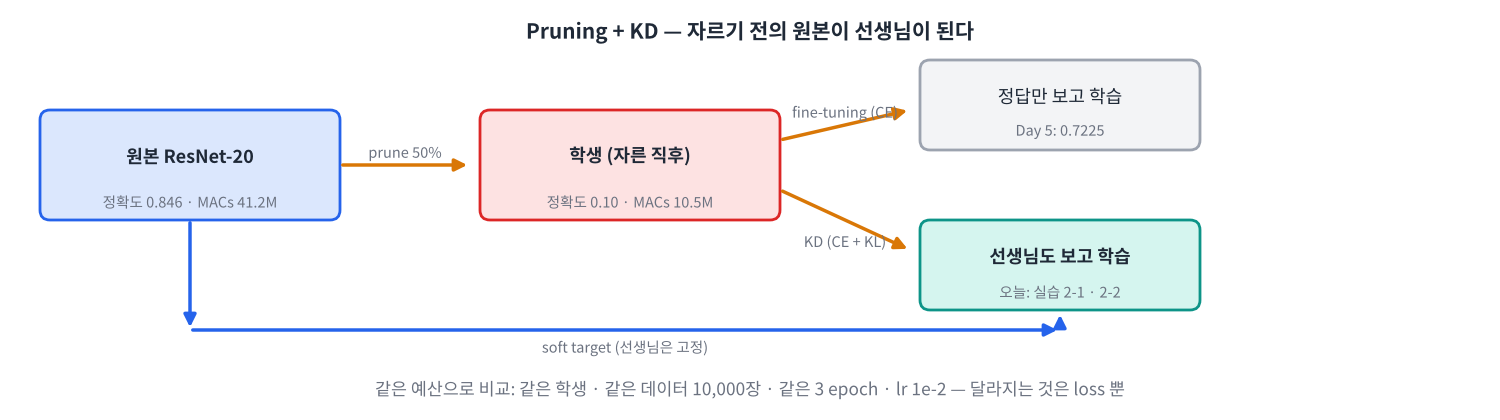

In [ ]:
#@title 🖼 그림 — Pruning + KD — 자르기 전의 원본이 선생님이 된다
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day6/img/f2_prunekd.png", embed=True, width=860))

**✍️ 직접 구현 2-1** `train_kd(student, teacher, epochs=EPOCHS, lr=1e-2, T=4.0, alpha=0.5, on_epoch=None)` 을 만드세요. 데이터 셀의 `finetune` 과 같은 구조 (SGD momentum 0.9 · weight_decay 5e-4 · step 마다 CosineAnnealingLR · 걸린 초를 돌려줌) 이고, 달라지는 것은 (1) 선생님을 `DEV` 로 옮겨 `eval()`, (2) step 마다 `torch.no_grad()` 로 선생님 logits 를 구해 `kd_loss` 를 쓰는 것입니다. 그리고 50% 가지치기 모델 `p50 = prune_channels(rn20, 0.5)` 의 복사본 `p50_kd` 를 KD 로 학습하며 epoch 별 정확도를 `hist_kd` (리스트, 맨 앞은 학습 전) 에 담으세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 4개).

In [ ]:
#@title 💡 힌트 2-1 — 실행할 때마다 하나씩
show_hint("2-1", "642w7J207YSwIOyFgOydmCBgZmluZXR1bmVgIOydhCDqt7jrjIDroZwg7Jiu6riw6rOgIOunqCDslZ7sl5AgYHRlYWNoZXIgPSB0ZWFjaGVyLnRvKERFVikuZXZhbCgpYCDsnYQg642U7ZWp64uI64ukLh5zdGVwIOyViDogYHdpdGggdG9yY2gubm9fZ3JhZCgpOiB0X291dCA9IHRlYWNoZXIoeGIpYCDihpIgYGxvc3MgPSBrZF9sb3NzKHN0dWRlbnQoeGIpLCB0X291dCwgeWIsIFQsIGFscGhhKWAuHmBwNTAgPSBwcnVuZV9jaGFubmVscyhybjIwLCAwLjUpYCwgYHA1MF9rZCA9IGNvcHkuZGVlcGNvcHkocDUwKWAsIGBoaXN0X2tkID0gW2FjY190b3JjaChwNTBfa2QpXWAuHmB0X2tkID0gdHJhaW5fa2QocDUwX2tkLCBybjIwLCBvbl9lcG9jaD1sYW1iZGEgZXAsIG06IGhpc3Rfa2QuYXBwZW5kKGFjY190b3JjaChtKSkpYC4=")

In [ ]:
# ✍️ 직접 구현 2-1 — train_kd · 50% 모델을 KD 로
def train_kd(student, teacher, epochs=EPOCHS, lr=1e-2, T=4.0, alpha=0.5, on_epoch=None):
    # TODO: finetune 과 같은 구조 — 선생님은 eval · no_grad, loss 는 kd_loss, 걸린 초를 돌려준다
    pass

p50 = None        # TODO: rn20 의 채널 50% 를 자른 모델
p50_kd = None     # TODO: p50 의 복사본
hist_kd = None    # TODO: [학습 전 정확도] 로 시작해 epoch 마다 추가
t_kd = None       # TODO: train_kd 실행 (걸린 초)
print(f"KD: {' → '.join(f'{a:.4f}' for a in hist_kd)} ({t_kd:.0f}초)")

In [ ]:
assert len(hist_kd) == EPOCHS + 1 and hist_kd[0] < 0.2 and hist_kd[-1] > 0.68 and t_kd > 0
assert not any(p.requires_grad and p.grad is not None for p in rn20.parameters()), "선생님은 학습하면 안 됩니다 (torch.no_grad)"
assert abs(acc_torch(rn20) - FP32_ACC) < 1e-9
print(f"✅ KD 로 50% 모델 {hist_kd[0]:.2f} → {hist_kd[-1]:.4f} — 선생님 (FP32 {FP32_ACC:.3f}) 은 그대로")

In [ ]:
#@title 🔒 정답 보기 2-1 — 강사가 알려 준 실습 2-1 잠금 코드를 입력하세요
show_answer("2-1", (
    "aHIIh43S78vNPvRtweCXdSjJlYBQWtTE2rJFrjUVbDGw7rPZ2aO1gBox2X1OZzGHG8ZYFpoB+So9ORlCADzCrzFx"
    "mzg0hUxo47SKwnq3h4bgjP8f6Tr+XBDt+yf7n8BgI6dY6ICTKVbzHuw7KbmS0E7dRJire0E4cVsWcZpA56rs0h1Q"
    "4x0gTOmuL98QnstC8ATRq2ZiJhy5FzmOvEzaCWCkWwCMdaXSViqV6XRq8KXLkZiY415EsxX+/TfquEpse8ggUSDQ"
    "BWkbH4SwPVYE2Yt5hIztY3qxaVgN0ZDmEDIpby/pOUZlgd/tDytUWyrVPugJ61ff19PDlyvY2w8zmgoHlTuZbQ/W"
    "r57Z0ldpWtf8R4JdAWzJITKfOMC0dSn+pNTi+NZDXl9W4liu1RBCq10QED2hcmihMoojGwJf8jE/lOntWxZG0ZXR"
    "8970Mi1NupsUJzUoqjog/XK9R+YWiqbIR6MgPjVMEvV1peJl+o6R3I4xaH4hxdJiTHFONvdfYwZjPh5MK5GvbAGb"
    "6UE3+C/p+FI/ZxACy8MEACfhjRGqkEkRdPnDbJFbAlO2wytIOIZUfy8zvqdvjZFexzHkVjkGhpx30PBzEuSREd3a"
    "Pn7Adcg6Kk7O+Fin5OcPNRF9QTCzkUL7jZKof5Om9MFhpEnXP/A7fliUdN99zHf9NXpJ8YBvwNa9apZzaH9c0l5h"
    "iV8vY3yrdZ3m0Yk9WQqA7azsm8Ch74QNNOtbSR/Ca0uDJKRCx0/ueL3ks7zDfEYAkmKbbA3AVpGJEJQSx/FnWmP/"
    "/Sp/aqmI0HepgDK8rTfS2VXESiyk0TzhVz8hiK+UDxPPGB26pNYd94ndUdlzGkaqs1HeoDXgqfKnCLR+sam2teBP"
    "juFXHQee3MGA3Xu+w7ZRUakxI0r5gvuL5FsbkIV1RZCMHJ3OERMb2boNdWV9lGbGek0ecmrIKa0VUKvqRjuU/QLu"
    "Y8sa0hlokXCUFOQVSPzjOs8RYB9gLJ+yi/ur2MH/LyarrBJNsTkud7jLpi3M4Jy7bOeCVpwgJG84p95AbmpitYxx"
    "4npQ5v4rwwH5MFhFPV0BUh06/U0JmkVSGnnBE3Ism9jM6puZX9ehQF4oF6wGaEx5s+WkJ6fdD/dtwQ4o0oaagxvi"
    "gD4zXB1dOCLCxajx06ydDNVpGYGPK1J1S11B4RDJCOiw9B0Ko9aOqX5c9U4puzEZG1iULo1DLHYzoNfEgGujSFJP"
    "BCXBcVSR7XpoMPFmp52XcOlkqFamh51IAUi3JC5tl3+Y+5tiKkHHcM/hrZ9td+tKmjr+ZDDsB75QAwKWZCJHGzFg"
    "34VQ/FaEBZpEn7P+lNjDim3nL5ZQAgocn7rYH0ZKaoxT0GR4vBWo3B7T5P4V2T2ArKY+115vp2wfnrE3LPnFHDBI"
    "SMtCMc607VLNpLG9vAeEYVIo+qUMtxUnx2M+k+Iv2j5EDbvZV70axUjA2cTdrvBnEIwZTWfaL6OvJCyxn8HHufsG"
    "8XPuF8QSBNTlenzwMh/ZmupKBav2A+G1RRjRDSsSu5aH590XCfRPcLv0IPGFjYkp3VT+Mo2YnV+TkLUVPPYle7z9"
    "z28GoUN8Seak3SfyDa5DWZZSnHf6Lg58sYzCa6se36SyFaUdHiZ67zgG8DpeAi6cMoNQ+S9d4oOASfOupjCur/X4"
    "afpnzVXrqzUY2Sz/CyTjlpmBxz8jlzIvE42J4yb4U/B/f8odKiSffKkhplst1dOsD3tZINr0luv8oH3tuseC5SvY"
    "8Lfy+c8AWVEdGPS+gGtSAT4sCZd0CDH9NGOTr9kD4hoTEAg9N3oqyhtxcikGNJIEry3tXtNpt/nCgA8H5FmFBJAY"
    "+NCcsbBAwo6pJfVCIrOFlT9+ZuzuNOviemwLpvRqdEiV8V8kQ29aWSmXruQMvR8U6UjbCKq46uLdb+1IeUSD0AFK"
    "IeY//UXYacgbdAkzUP6YZgnSPyokWicmuC1ztarOKixxDPFGVTmKUX8="
))


**✍️ 직접 구현 2-2** 같은 `p50` 의 또 다른 복사본 `p50_ft` 를 **일반 fine-tuning** (`finetune`, 같은 3 epoch · lr 1e-2) 으로 학습하고, 두 방법을 `kd_df` (열 `method, acc, train_s` — 행 `fine-tuning`, `KD`) 로 비교하세요. KD 의 이득 `kd_gain = KD 정확도 − fine-tuning 정확도` 를 구하고, KD 모델을 `torch.save(p50_kd.cpu(), "rn20_p50_kd.pth")` 로 저장하세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 2-2 — 실행할 때마다 하나씩
show_hint("2-2", "YHA1MF9mdCA9IGNvcHkuZGVlcGNvcHkocDUwKWAg4oaSIGB0X2Z0ID0gZmluZXR1bmUocDUwX2Z0KWAuHmBrZF9kZiA9IHBkLkRhdGFGcmFtZShbeyJtZXRob2QiOiAiZmluZS10dW5pbmciLCAiYWNjIjogYWNjX3RvcmNoKHA1MF9mdCksICJ0cmFpbl9zIjogdF9mdH0sIHsibWV0aG9kIjogIktEIiwgImFjYyI6IGhpc3Rfa2RbLTFdLCAidHJhaW5fcyI6IHRfa2R9XSlgLh5ga2RfZ2FpbiA9IGZsb2F0KGtkX2RmLmFjY1sxXSAtIGtkX2RmLmFjY1swXSlgIMK3IGB0b3JjaC5zYXZlKHA1MF9rZC5jcHUoKSwgInJuMjBfcDUwX2tkLnB0aCIpYC4=")

In [ ]:
# ✍️ 직접 구현 2-2 — fine-tuning vs KD (같은 예산)
p50_ft = None     # TODO: p50 의 또 다른 복사본을 finetune
kd_df = None      # TODO: 열 method, acc, train_s — 행 fine-tuning, KD
kd_gain = None    # TODO
# TODO: KD 모델 저장 — rn20_p50_kd.pth
display(kd_df.round(4)); print(f"KD 이득 {kd_gain * 100:+.2f}%p | FP32 와의 차이 {(FP32_ACC - kd_df.acc[1]) * 100:.1f}%p")

In [ ]:
assert kd_df.method.tolist() == ["fine-tuning", "KD"] and (kd_df.acc > 0.65).all() and abs(kd_gain - (kd_df.acc[1] - kd_df.acc[0])) < 1e-9
assert os.path.exists("rn20_p50_kd.pth") and abs(kd_df.acc[1] - hist_kd[-1]) < 1e-9
print(f"✅ 같은 예산 — fine-tuning {kd_df.acc[0]:.4f} vs KD {kd_df.acc[1]:.4f} ({kd_gain * 100:+.2f}%p)")

In [ ]:
#@title 🔒 정답 보기 2-2 — 강사가 알려 준 실습 2-2 잠금 코드를 입력하세요
show_answer("2-2", (
    "wVk0mqaIFvVu6x7HzxAE/+u9S584g48mfJUm7Xn2HL1ZugIDud2pNueeAc1a4gq/J0iQjE4ZAlKHS7JwFGJKi/eg"
    "EI0xdeY4CsaI0a0g4WWRkNt4ViX+03YmuyYVtbzxOSAOAFq3lUgmlErXe9VnJG5nCaqcvcZ+WGyABvE8mED44LlE"
    "b4ah4v1Q977EpqLp/ef96esBJynbu5unKIfps9E8mSMMS14JSD94UA4w7SYQ1XX/vIEVJ2YcA8JlOnWsedzMwLAm"
    "x1oDEl1qwvUDpk/o9lR8ijGLtfi5aP4OuuZ/OW3hxpbG91alM32ZJnNzoGk4bmM0FNiG0h0y+bUTojjmvgLnLEnA"
    "Bi2DGY0CnEdCm5O7vqqfUhni+JtUYD51F23PFtrZ+2shtL0BAdlYh/zmKMTqFW9ZcXXtUGe2kMhPILwj6R8Nrq/n"
    "eCVPzznlPYfnYztgrj05HQJy2V2/Tf3HsVH/jwy6tViiKo3aUbyoF9dyRh0XU/YXZs/LcnQYyYs6H1reNIJ8bZRF"
    "oCCbbNE3N/j3On2S/A6w6ZVd8sg9KLqYhP1MM68OcAaei1V0C4gY6TGlPh+qab7VJjrNdUTtwwzjoIQX+d0IXXBH"
    "z9GWsmc6xbSchhwSByALXRJGYhWhOtKkvulVVigkXBiqG6O8qrdO7GUrehOYPbNyWXfzcePDCi2WydarYVfjByVq"
    "2phugULGkRb6/4zJij5axQDZtC9OJkeEVSPIlIZKj75gUfcpNIiPOIZUsLQM734slR46HVJSMeY0FLVXII9i9O6c"
    "8G/Bc6+mB8TnfM388x9WY2/FUsAC4Sw1tHF8YAuXAYE/IGqFFh5EOYspGK+ItyWwEoY7c1pkNk43sdWd6EiKG7S7"
    "HzKCjm80vzGQr7r2pU4oFXxre2JaVHHywJYhpAmMY60LQ5rBZHmP2nCVJNdQC5NfkPTshLNzeP6ZOQ9W7cDhnMiT"
    "Zo5mQW52X0WTS98XuVLkqA/ZWzwsUxIFwazcDhkuaik67AZkhqhFd20pr5r8IKKU9DPQGWupRmo9g9nE9UcDb/ZS"
    "XOrQceA4oTMhiPl49Fou5/ehqxaT3IaZkq+nHKYn3ON4dIU37feaFr9Kk/bN5Es5H7e2Eo45Ejk0EWTO9abpqF3C"
    "qOYGhZkU3sW4Odkfyl+OdafDxnz39JOIvTsH10tuSgLK5PsgPS4hLS9Z5o/0S/lvZwUc0JHe+3HkziBB4GkN6g=="
))


**▶ 예제 2-A (제공 코드 — 실행만)** Day 5 미니 프로젝트에서 고른 **20% 모델** 에도 fine-tuning 과 KD 를 같은 예산으로 적용해 `kd20_df` 로 비교합니다. Day 5 의 기준선 (FP32 − 3%p = 0.816) 과 견주어 보세요. (학습 2번 — CPU 약 2분)

> 이 셀은 **직접 구현이 아닙니다.** 그대로 실행하고, 출력과 아래 해설을 읽어 보세요.

In [ ]:
# ▶ 예제 2-A — 제공 코드 (그대로 실행)
p20 = prune_channels(rn20, 0.2)
p20_ft, p20_kd = copy.deepcopy(p20), copy.deepcopy(p20)
finetune(p20_ft); train_kd(p20_kd, rn20)
kd20_df = pd.DataFrame([{"method": "fine-tuning", "acc": acc_torch(p20_ft)}, {"method": "KD", "acc": acc_torch(p20_kd)}])
display(kd20_df.round(4))
print(f"20% 모델 (MACs {macs_m(p20):.1f}M): KD 이득 {(kd20_df.acc[1] - kd20_df.acc[0]) * 100:+.2f}%p | FP32 대비 {(kd20_df.acc[1] - FP32_ACC) * 100:+.2f}%p")

In [ ]:
assert (kd20_df.acc > 0.78).all()
print(f"✅ 20% 모델 — fine-tuning {kd20_df.acc[0]:.4f} · KD {kd20_df.acc[1]:.4f}")

> 💡 **예제 2-A 해설** — 강사 실측: 20% 모델 fine-tuning 0.8195 → KD 0.8215 (+0.2%p, FP32 대비 −2.45%p). 덜 자른 모델은 이미 정답만으로도 많이 회복하므로 KD 의 이득이 작습니다 — KD 는 **많이 망가진 학생일수록** 더 도움이 됩니다. KD 는 '공짜 점심' 이 아니라 '같은 예산에서 조금 더' 입니다. 1%p 기준 안에 들려면 데이터 · epoch 도 함께 늘려야 합니다.

#### 📌 2교시 정리

- 가지치기에서는 **자르기 전의 원본이 선생님** — 따로 큰 모델을 학습할 필요가 없다.
- 같은 예산 (10,000장 · 3 epoch) 에서 50% 모델: fine-tuning 0.72 → KD 0.75. 덜 자른 모델일수록 이득은 작다.
- KD 는 학습 때만 선생님이 필요하다. 배포되는 것은 학생뿐.

## 3교시 — 순서의 문제: Prune → KD → INT8 → TensorRT

지금까지 배운 기법을 **한 모델에 차례로** 적용합니다. 순서가 중요합니다.

```
① Prune (구조 확정)  →  ② KD · fine-tuning (정확도 회복)  →  ③ INT8 (PTQ → 손실이 크면 QAT)  →  ④ QDQ ONNX → TensorRT
```

| 순서 | 왜 |
|---|---|
| **구조를 먼저** (prune) | 채널 수가 바뀌면 그 뒤의 모든 것 (weight · 양자화 범위) 이 다시 정해져야 한다 |
| **회복을 그다음** (KD) | 양자화 범위 (scale) 는 **최종 weight · 활성값** 으로 정해야 한다 |
| **양자화를 마지막** (INT8) | 양자화기는 채널별 scale 을 **채널 수만큼** 들고 있다 — 그 뒤에 채널을 자르면 맞지 않는다 |
| PTQ 를 먼저, QAT 는 필요할 때만 | Day 4 의 기준: PTQ 손실이 1%p 를 넘을 때만 QAT |

> 양자화를 먼저 하고 가지치기를 하면? — 실습 3-2 에서 직접 해 봅니다.

> 🎬 **애니메이션** [D6-3 순서의 문제](https://imguru-mooc.github.io/AI_CAMPUS/QP-day6/animation.html#d6-3)
> 애니메이션은 **이 교시의 노트북 순서 그대로**입니다 — 단계마다 먼저 **예측**을 고르고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

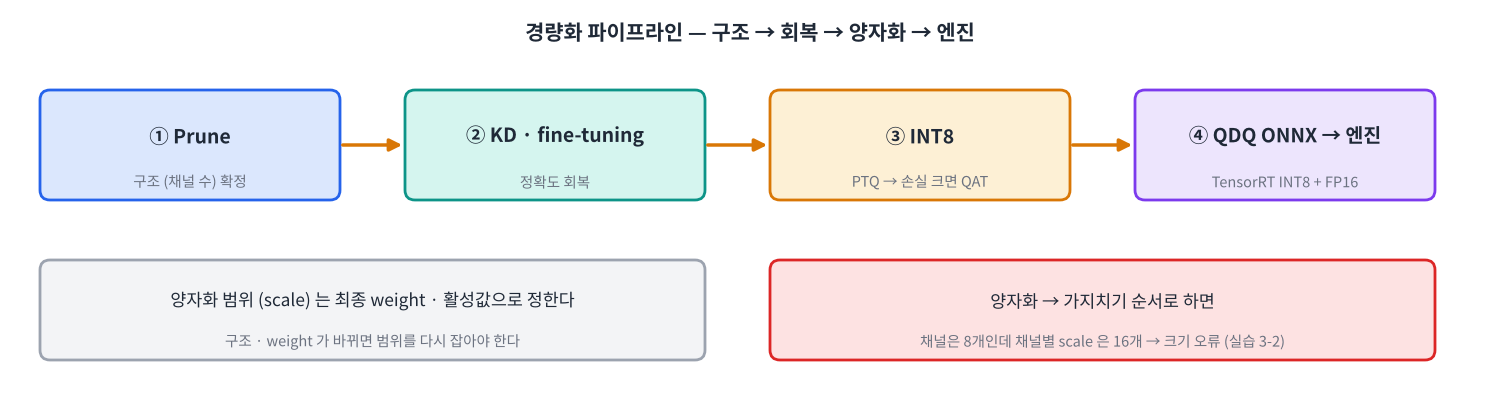

In [ ]:
#@title 🖼 그림 — 경량화 파이프라인 — 구조 → 회복 → 양자화 → 엔진
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day6/img/f3_order.png", embed=True, width=860))

**✍️ 직접 구현 3-1** (1) 모델의 **복사본** 을 ModelOpt 로 INT8 PTQ 해 돌려주는 `to_int8(model)` 을 만드세요 (Day 4 실습 5-1: `mtq.quantize(복사본.to(DEV), mtq.INT8_DEFAULT_CFG, forward_loop=forward_loop)`). (2) KD 모델 `p50_kd` 를 양자화한 `q_kd` 의 정확도 `acc_int8` 과 양자화 전 정확도 `acc_kd` 로 `need_qat = (acc_kd − acc_int8) > 0.01` 을 판정하세요. (3) `q_kd` 의 복사본을 `rn20_p50_kd_int8.onnx` 로 내보내 (`export_b1`) ORT 정확도 `acc_int8_onnx` 를 구하세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 3-1 — 실행할 때마다 하나씩
show_hint("3-1", "YHRvX2ludDhgOiBgbXRxLnF1YW50aXplKGNvcHkuZGVlcGNvcHkobW9kZWwpLnRvKERFViksIG10cS5JTlQ4X0RFRkFVTFRfQ0ZHLCBmb3J3YXJkX2xvb3A9Zm9yd2FyZF9sb29wKWAg4oCUIGB3aXRoIHF1aWV0KCk6YCDroZwg6rCQ7Iu466m0IOq4tCDroZzqt7jqsIAg7Iio6rKo7KeR64uI64ukLh5gcV9rZCA9IHRvX2ludDgocDUwX2tkKWAgwrcgYGFjY19rZCwgYWNjX2ludDggPSBhY2NfdG9yY2gocDUwX2tkKSwgYWNjX3RvcmNoKHFfa2QpYCDCtyBgbmVlZF9xYXQgPSAoYWNjX2tkIC0gYWNjX2ludDgpID4gMC4wMWAuHmBleHBvcnRfYjEoY29weS5kZWVwY29weShxX2tkKSwgInJuMjBfcDUwX2tkX2ludDgub25ueCIpYCDihpIgYGFjY19pbnQ4X29ubnggPSBvbm54X2FjYygicm4yMF9wNTBfa2RfaW50OC5vbm54IilgLg==")

In [ ]:
# ✍️ 직접 구현 3-1 — 가지치기 + KD 모델을 INT8 로
def to_int8(model):
    # TODO: 복사본을 ModelOpt INT8 PTQ
    pass

q_kd = None             # TODO
acc_kd = acc_int8 = None    # TODO: 양자화 전 · 후 정확도
need_qat = None         # TODO: 손실이 1%p 를 넘는가
acc_int8_onnx = None    # TODO: rn20_p50_kd_int8.onnx 로 내보내 ORT 정확도
print(f"KD {acc_kd:.4f} → INT8 PTQ {acc_int8:.4f} (손실 {(acc_kd - acc_int8) * 100:+.2f}%p) → need_qat {need_qat} | QDQ ONNX {acc_int8_onnx:.4f} · {trt_check('rn20_p50_kd_int8.onnx')}")

In [ ]:
assert q_kd is not p50_kd and not any("quantizer" in n for n, _ in p50_kd.named_modules()), "원본 p50_kd 는 양자화되면 안 됩니다 (복사본에)"
assert abs(acc_kd - acc_int8) < 0.03 and need_qat == ((acc_kd - acc_int8) > 0.01)
assert trt_check("rn20_p50_kd_int8.onnx")["ok"] and abs(acc_int8_onnx - acc_int8) < 0.01
print(f"✅ 가지치기 + KD 모델도 INT8 PTQ 손실 {(acc_kd - acc_int8) * 100:+.2f}%p — QAT {'필요' if need_qat else '불필요'}")

In [ ]:
#@title 🔒 정답 보기 3-1 — 강사가 알려 준 실습 3-1 잠금 코드를 입력하세요
show_answer("3-1", (
    "hvXK8xLUJOHBRydXV/4urmvWehLZMyW6dOd376pfaJhNqbpACTpzt63cnajnBiKpou4l/SezYKd+jC+/dudGQxLs"
    "ITrJ8XI3O228PvYYwJI0mHlKDDBtzdwPGSNoaK8CFTwQdO1Mw4YqFOQ1M+IModfzafVhR3wDR1gK7AvPFeg4fvVw"
    "sJ4dM0thWIa45NHvn1kAmD0qiCmEacWCnhp4ILzFqpr6pmejZYTF2J2KzUQVlv72RcUCF/em5Olu1wdJNCGpEOAe"
    "p5tq/qyvTLf5iRr1cspIQaf7S4ZBxvpqos4H2zwbZn7LMqSGZCcmcWQ9mTQdakCNkb/OXccRhO/Y09rt/5vc2l2g"
    "YUVCeSdFnZWiyCJ6ok3TimZ6e7JY2rZ7g/ZgGmSqu4sdHbQoSdFMjDKNZNQxrjzsYDcVldrO4HtKoPlvgayYkodi"
    "rPaRTl11sHsToxr8PZp4vMa52TrMDB/HxaJC0SWKRkPfjtXZuJLm8ZTdCdVBaFoirr9mpm2Ia0I5zsEORTOBB+CX"
    "M0bmdjwrWEuVnKKFEATF3ixvng5rs6gQ/THW149aYkFbgZAWKdpclNLt3l9DLpmTW2GN0h50Npq7PLrMJJL64Fi0"
    "7kHy6ep+wnBA6nsBqd1Gqnzf05TkJ/TkajffCQitt6AbtiIjRviqFC6cL86CICjH5CrcLdTiEJFi5ez5Waf+x09g"
    "IObg5ckm7Cqyq2IRMcidLRAL01iKXPMBzT/p7MRYgx6SZBgxG+OCG+UrKTJ7nVi9Ns0DKjFRJsUvPLBQPqnhbx0f"
    "6ymcZpajZqF8b4peZfly8nlkjwG1GW2HCaqZWToavXIhJtYpR5XKwp8pe0ZEz6+7fSCqlF8YHp5MRgj/YTOHCHWq"
    "VzMbgJn7CZjXQsm4Aizoy/izANm/ERcnTkQ1j6Vm7FrdTewjmzL5vX1rgX4WBQbu+F8y7yHbyEXv5erjigt9IxHH"
    "CvMaamUDOQ6TlIOQpLc7x9e2Zx5osN/AGV/UR8qzBNZxuDTHbWgbBe4VYROydpexsBmNHL5++ZMlFnJ2vpvqJEuC"
    "/ESOgxknntXQ/1L9fEdEZF7U3WrfRvLYIjjts7FIbhocZtmVxcTvVhsJHOIuSv5gzqukATV/V1kdeDSfTE/7Wcre"
    "T4S8VvHHr/439PnEfREgU9/h2enqRfu6NQk/C93FybJuR1m3Gr9AbV1yi/gZyBNkMtZADEyBIeY5GFAAxUvymg1d"
    "gOZgjw67eCl8DZeRivTwiZ5r0f4VTXvTHQ3HEqxFp+XKA37bK+Fm/JPVS1foSroMAIMVmW5Ejngw9l2rzTQ5M1rU"
    "chYyy4wuYW/PVM6sgS007M9ekf5BpB339dKZ6CI4FjzwyiOJdTlz1oZUQnE1/2vP1kwUSoacujbHW4mtHzCZGLE3"
    "ep115MWu64zTY6fm9hb6hScwTUFHMeUq0jHk/RFo2SaWHBr8JSw97ZDIF4PlrF8XRl0gEc6Ao/03sYmMbfF2baWq"
    "bn9sQPjRgiyGwUPLmWynUpEatvGTRtEVLBCDySimGxM="
))


**✍️ 직접 구현 3-2** 순서를 바꿔 봅니다: **양자화 먼저 → 가지치기**. (1) 원본 `rn20` 을 `to_int8` 로 양자화한 `q_first` 의 정확도 `acc_q_first` 를 구하세요. (2) `q_first` 의 복사본 (`.cpu().eval()`) 에 `make_pruner(m_bad, 0.5).step()` 으로 채널 50% 를 자른 뒤 `acc_torch(m_bad)` 를 실행해, 나는 `RuntimeError` 메시지를 `err_order` 에 담으세요 (오류가 없으면 `None`).

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 3-2 — 실행할 때마다 하나씩
show_hint("3-2", "YHFfZmlyc3QgPSB0b19pbnQ4KHJuMjApYCDCtyBgYWNjX3FfZmlyc3QgPSBhY2NfdG9yY2gocV9maXJzdClgLh5gbV9iYWQgPSBjb3B5LmRlZXBjb3B5KHFfZmlyc3QpLmNwdSgpLmV2YWwoKWAg4oaSIGBtYWtlX3BydW5lcihtX2JhZCwgMC41KS5zdGVwKClgLh5gdHJ5OiBhY2NfdG9yY2gobV9iYWQpOyBlcnJfb3JkZXIgPSBOb25lYCAvIGBleGNlcHQgUnVudGltZUVycm9yIGFzIGU6IGVycl9vcmRlciA9IHN0cihlKWAu")

In [ ]:
# ✍️ 직접 구현 3-2 — 순서를 바꾸면: 양자화 → 가지치기
q_first = None        # TODO: 원본을 먼저 양자화
acc_q_first = None    # TODO
m_bad = None          # TODO: q_first 복사본 (cpu · eval) 의 채널 50% 를 자른다
err_order = None      # TODO: acc_torch(m_bad) 에서 나는 RuntimeError 메시지
print(f"양자화만: {acc_q_first:.4f} | 그 뒤 가지치기 → conv1 weight {tuple(m_bad.layer1[0].conv1.weight.shape)} · weight 양자화기 amax {m_bad.layer1[0].conv1.weight_quantizer.amax.numel()}개")
print("forward →", err_order)

In [ ]:
assert acc_q_first > 0.83 and err_order is not None and "size of tensor" in err_order
assert m_bad.layer1[0].conv1.weight.shape[0] != m_bad.layer1[0].conv1.weight_quantizer.amax.numel()
print("✅ 채널은 줄었는데 채널별 scale (amax) 은 예전 개수 그대로 — 양자화 뒤에 구조를 바꾸면 깨진다")

In [ ]:
#@title 🔒 정답 보기 3-2 — 강사가 알려 준 실습 3-2 잠금 코드를 입력하세요
show_answer("3-2", (
    "mfmBfXYO+vfgWGY6IBJnhLw4sDktXoDafIBfF5K6TLeNUhwnSCfuc4ryh18a6TCur2sv9YizpiJw/moCorAWHN+g"
    "MdnH5uAj1WYPoXQrzLZ2FAvaw0o/wzx/RbIhBp7pn2hzKbhoAGEq+n8OfI4Pmrk7tmGRWvoXb6WsEpuR86Fhy12G"
    "HMDD2bSBey/OrpYqIW3ocVfMnRaGrxf9DObvMtyIUZo4SGDD8Y62L0T3L2ZGP8pBZB+NFivCSp0ccFJ7WbzGJKmU"
    "DmRup+W8X3/OuPgNmZHyJGDDYn9wNB3qIRHSBudysSuVrEFoYiE0NL61XzLoOb95uK3alVlTHyepBRpBgkXCU0yl"
    "pmgM61rK1se/kDiJaEfxX3RlDEOMZXfeuO/axZ5NoxtrtgyHeSC6wWNMnMt/tczK+XknX0RvJ9lTxMVifEvDmTIh"
    "kkFmPkCPP39mv0gOeTe18eBmof1PbLsPP4hM3U1HNvZlRBxwBS+BiWqG0odD0BAu3gyZu8MuHRZdWjUiRDjYHU44"
    "zsr8HS7s6O0yl/g3KMNWmrsU3zrw7PX0qEQIN+s6xrkqIICabYglDGB7vpVURMr7s5M5D8uhvHJ0W+mJi2CQjQpT"
    "aE9LhbEnKgpu/yaoUAwyzp5lc9IRtwwgsGQXkPb6iUkcM9SqsNBhFXm0Q+38+kzR7YFXZGdoTpU0tsbnve75wT8T"
    "JbBfWAK2kKj11/ye6ozhhJGihbPUyIvHf6MVpjv/H6rn2Fsik+lNR8OQ9nAhRfBSNsQTn3Le94+Og40HSfaSGMw1"
    "MRmn03LPttF+K8D4mtjHy4ao7ay+y2yeES37RNuLwhu2Puww6cTAhYTCn5PzOFHfu4+0e1oEXh1pPnc/4+p+NTzF"
    "WosGa/8EIkSA/EwxNeQVu5x7KW+w9mJdTBEGTY5UBsaAirn/9oqCLf8PMkwgTVUL0liLMtKdHE4CoIlvNy86Jkvp"
    "BvYjUOOTHHVBi7ZDpyd1iyGUFonxub4VQIXC+Zo2kqebBcUm2DNfdd3rBFJ8iL2OuI550NrJKRPoooFgK3fVJ5ch"
    "Z9CYRVDKThrcSFN27laqxxoTIrZBKbY83vHyLlfViiLd21CDhBmRA1Df/cphsIq0qqPHOmJ4QAQ8Mk2vwom69ICG"
    "itr1F9NIL54qbb4J1OdYO+Nf2gVsPcAu4yw2oxY2q9ScZQBVDDEP2vklhltf23AFL1KbmjFV54WgJ8sT4cTxf8l5"
    "5r5gWBOJqCwmPBDW8SCoc6zfs+tntyqbRe2lRuHnByvBluhYgtdCZ0/godMrTojy400KPzkN0sz7A4XMz7nBo42R"
    "gvqDJjCJ/BXtYrKsh+Xx46ehryHTiP3OT4aslI9icvnlheL4aSeSQzXjcNHYv667uKyUfTVzCoaMWk1fliu8Qi+1"
    "RhYIBEBIeMMn40Rn0Q=="
))


**▶ 예제 3-A (제공 코드 — 실행만)** 오늘 1 ~ 3교시에 만든 함수를 순서대로 묶은 `compress(model, teacher, ratio)` 와, 그 함수들의 소스를 모은 **`compress.py`** 를 만듭니다. 그리고 지금까지의 단계별 결과를 `pipe_df` (열 `stage, macs_m, acc, onnx_kb`) 로 정리합니다 (`compress` 를 다시 실행하지는 않습니다 — 단계별 실행은 실습 2-1 ~ 3-1 에서 이미 했습니다).

> 이 셀은 **직접 구현이 아닙니다.** 그대로 실행하고, 출력과 아래 해설을 읽어 보세요.

In [ ]:
# ▶ 예제 3-A — 제공 코드 (그대로 실행)
def compress(model, teacher, ratio=0.5, epochs=EPOCHS, out="compressed_int8.onnx"):
    m = prune_channels(model, ratio)             # ① 구조를 먼저 확정
    train_kd(m, teacher, epochs=epochs)          # ② 정확도 회복 (KD)
    q = to_int8(m)                               # ③ 양자화 — PTQ (손실이 크면 QAT 를 더한다)
    export_b1(copy.deepcopy(q), out)             # ④ QDQ ONNX → TensorRT INT8 + FP16
    return m, q

_src = "\n\n".join(inspect.getsource(f) for f in [make_pruner, prune_channels, soft, kd_loss, train_kd, to_int8, compress])
open("compress.py", "w", encoding="utf-8").write("# compress.py — Prune → KD → INT8 → QDQ ONNX (QP Day 6)\n" + _src)

export_b1(copy.deepcopy(rn20), "rn20_fp32.onnx"); export_b1(copy.deepcopy(p50_kd), "rn20_p50_kd.onnx")
pipe_df = pd.DataFrame([
    {"stage": "FP32 원본", "macs_m": macs_m(rn20), "acc": FP32_ACC, "onnx_kb": size_kb("rn20_fp32.onnx")},
    {"stage": "① prune 50%", "macs_m": macs_m(p50), "acc": acc_torch(p50), "onnx_kb": np.nan},
    {"stage": "② + KD", "macs_m": macs_m(p50_kd), "acc": acc_kd, "onnx_kb": size_kb("rn20_p50_kd.onnx")},
    {"stage": "③ + INT8 (PTQ)", "macs_m": macs_m(p50_kd), "acc": acc_int8_onnx, "onnx_kb": size_kb("rn20_p50_kd_int8.onnx")}])
display(pipe_df.round(4)); print("compress.py", len(open("compress.py", encoding="utf-8").read().splitlines()), "줄")

In [ ]:
assert os.path.exists("compress.py") and "def compress" in open("compress.py", encoding="utf-8").read() and len(pipe_df) == 4
print(f"✅ 파이프라인 — MACs {pipe_df.macs_m[0]:.1f}M → {pipe_df.macs_m[3]:.1f}M · 정확도 {pipe_df.acc[0]:.3f} → {pipe_df.acc[3]:.3f}")

> 💡 **예제 3-A 해설** — QDQ ONNX 는 weight 가 아직 FP32 라 파일이 FP32 ONNX 보다 조금 큽니다 (Day 4 7교시) — 진짜로 작아지는 것은 TensorRT 엔진입니다. MACs 는 양자화로 변하지 않습니다 (연산 횟수는 같고, 한 번의 연산이 싸질 뿐). `compress.py` 는 오늘의 산출물입니다. 다른 모델에 쓰려면 `ignored_layers` (출력 층) · 데이터 로더 · 보정 데이터만 바꾸면 됩니다.

#### 📌 3교시 정리

- 순서: **구조 (prune) → 회복 (KD) → 양자화 (INT8) → 엔진**. 양자화 범위는 최종 weight 로 정한다.
- 양자화 뒤에 채널을 자르면 채널별 scale 이 맞지 않아 깨진다.
- 가지치기 + KD 모델도 8비트는 PTQ 로 충분했다 (need_qat False) — 그래도 항상 재 보고 판정한다.

## 4교시 — 탐지 모델 경량화: YOLOv8n INT8 · INT8-mixed 준비

오후에는 분류 모델 (ResNet-20) 에서 **탐지 모델 (YOLOv8n)** 로 넘어가, OT Day 5 의 **침입 감지 파이프라인**에 경량화한 엔진을 넣습니다.

**재학습 없이 할 수 있는 것 / 없는 것**

| 기법 | 재학습 | 오늘 YOLOv8n 에 | 이유 |
|---|---|---|---|
| FP16 | 불필요 | ✅ 기준 엔진 | 플래그 하나 (OT Day 5) |
| INT8 PTQ (QDQ) | 불필요 — **보정 데이터만** | ✅ | Day 3 — Detect head 후처리는 제외 |
| INT8 mixed precision | 불필요 | ✅ | 예민한 층 (첫 Conv · 출력 Conv) 을 더 제외 |
| QAT · structured pruning · KD | **필요** (COCO 학습 데이터 · 수 시간) | ❌ 오늘은 하지 않음 | 12월 프로젝트에서 자기 데이터로 fine-tuning 할 때 적용 |

**보정 데이터는 배포 환경에서** — Day 3 에서는 Penn-Fudan 사진으로 보정했습니다. 오늘은 **실제로 돌릴 카메라 영상 (`people.mp4`) 의 앞부분 프레임** 으로 보정합니다. 활성값 범위는 입력 분포에 따라 달라지므로, 배포할 장면으로 보정하는 것이 가장 좋습니다. 단 **보정에 쓴 구간과 평가하는 구간은 나눕니다.**

| 구간 | 프레임 | 용도 |
|---|---|---|
| 앞부분 | 0 ~ 479 (10프레임마다 1장 = 48장) | 보정 (calibration) |
| 뒷부분 | 480 ~ 794 | 평가 — 침입 이벤트가 모두 이 구간에 있음 |

> 엔진 이름: **FP16** (기준) · **INT8** (Detect head 후처리만 제외) · **INT8-mixed** (+ 첫 Conv · 마지막 출력 Conv 6개 제외). GPU 가 없으면 같은 ONNX 를 ONNX Runtime CPU 로 돌립니다 (이때 "FP16" 은 FP32 ONNX 입니다).

In [ ]:
# ▶ 데이터 · 모델 셀 (2) — YOLOv8n · people.mp4 · 침입 감지 함수 (VB Day 4 · OT Day 5 · QP Day 3 에서 만든 것)
VIDEO, YOLO_ONNX = fetch("people.mp4"), fetch("yolov8n.onnx")
_cap = cv2.VideoCapture(VIDEO); V_FPS = _cap.get(cv2.CAP_PROP_FPS); N_FRAMES = int(_cap.get(cv2.CAP_PROP_FRAME_COUNT)); _cap.release()
EVAL_START = 480                                             # 0 ~ 479 는 보정용, 480 ~ 는 평가용
SEG = (0, None) if TRT_OK else (EVAL_START, None)            # 파이프라인을 돌릴 구간 (시작 프레임, 프레임 수) — CPU 는 뒤쪽만
GRASS = np.array([(0, 270), (180, 300), (380, 350), (520, 470), (560, 575), (0, 575)], np.int32)   # 위험구역 (잔디)

def read_frames(idx):
    # 영상에서 번호가 idx 인 프레임들을 읽어 리스트로
    cap = cv2.VideoCapture(VIDEO); out = []; want = set(idx); i = 0
    while want:
        ok, f = cap.read()
        if not ok: break
        if i in want:
            out.append(f); want.discard(i)
        i += 1
    cap.release(); return out

def iou(box, boxes):
    x1 = np.maximum(box[0], boxes[:, 0]); y1 = np.maximum(box[1], boxes[:, 1]); x2 = np.minimum(box[2], boxes[:, 2]); y2 = np.minimum(box[3], boxes[:, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    return inter / ((box[2] - box[0]) * (box[3] - box[1]) + (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1]) - inter + 1e-9)

def nms(boxes, scores, iou_thr=0.7):
    order = np.argsort(-scores); keep = []
    while order.size > 0:
        i = order[0]; keep.append(i); rest = order[1:]
        order = rest[iou(boxes[i], boxes[rest]) <= iou_thr]
    return np.array(keep, dtype=int)

def letterbox(img, size=640, color=114):
    h, w = img.shape[:2]; r = min(size / h, size / w)
    nw, nh = round(w * r), round(h * r)
    resized = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_LINEAR)
    top, left = (size - nh) // 2, (size - nw) // 2
    out = np.full((size, size, 3), color, dtype=np.uint8); out[top:top + nh, left:left + nw] = resized
    return out, r, (left, top)

def to_input(img):
    lb, r, pad = letterbox(img)
    return (lb[..., ::-1].transpose(2, 0, 1)[None] / 255.0).astype(np.float32), r, pad

def decode_yolo(out, conf_thr=0.25, iou_thr=0.7, cls=0):
    p = np.asarray(out)[0].T                              # (8400, 84)
    boxes_c, cls_scores = p[:, :4], p[:, 4:]
    best, conf = cls_scores.argmax(1), cls_scores.max(1)
    m = (conf > conf_thr) & (best == cls)
    cx, cy, w, h = boxes_c[m].T
    boxes = np.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], 1)
    keep = nms(boxes, conf[m], iou_thr)
    return boxes[keep], conf[m][keep]

def detect(frame, infer, conf=0.25, iou_thr=0.7):
    x, r, (pl, pt) = to_input(frame)
    boxes, scores = decode_yolo(infer(x), conf, iou_thr)
    boxes = (boxes - [pl, pt, pl, pt]) / r
    H, W = frame.shape[:2]
    boxes[:, [0, 2]] = boxes[:, [0, 2]].clip(0, W); boxes[:, [1, 3]] = boxes[:, [1, 3]].clip(0, H)
    return boxes, scores

def in_zone(pt, poly=GRASS):
    return cv2.pointPolygonTest(poly, (float(pt[0]), float(pt[1])), False) >= 0

def foot_points(boxes):
    boxes = np.asarray(boxes, float).reshape(-1, 4)
    return np.stack([(boxes[:, 0] + boxes[:, 2]) / 2, boxes[:, 3]], 1)

def draw_result(frame, boxes, inside, alarm, poly=GRASS, tag=None):
    # 구역 · 박스 · 발 위치 · 경보 · 엔진 이름을 그린 새 프레임
    ov = frame.copy(); cv2.fillPoly(ov, [poly], (0, 0, 255))
    out = cv2.addWeighted(ov, 0.45 if alarm else 0.15, frame, 0.55 if alarm else 0.85, 0)
    cv2.polylines(out, [poly], True, (0, 0, 255), 2)
    for b, f_, ins in zip(np.asarray(boxes).astype(int), foot_points(boxes).astype(int), inside):
        col = (0, 0, 255) if ins else (0, 200, 0)
        cv2.rectangle(out, tuple(b[:2]), tuple(b[2:]), col, 2); cv2.circle(out, tuple(f_), 4, col, -1)
    cv2.putText(out, f"people {len(boxes)}  in zone {int(np.sum(inside))}", (10, 28), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2)
    if tag:
        cv2.putText(out, tag, (out.shape[1] - 200, 28), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 255), 2)
    if alarm:
        cv2.putText(out, "INTRUSION ALARM", (10, 64), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 0, 255), 3)
    return out

def process_frame(frame, infer, streak, n_consec=3, conf=0.25, tag=None):
    # OT Day 5 과제 1 — 한 프레임: 탐지 → 구역 판정 → 연속 n_consec 프레임이면 경보
    boxes, scores = detect(frame, infer, conf=conf)
    inside = np.array([in_zone(p) for p in foot_points(boxes)], bool)
    streak = streak + 1 if inside.any() else 0
    alarm = int(streak >= n_consec)
    vis = draw_result(frame, boxes, inside, alarm, tag=tag)
    return vis, {"n_people": len(boxes), "n_inside": int(inside.sum()), "alarm": alarm}, streak

def find_events(alarm, fps, first=0):
    # OT Day 5 과제 3 — 경보 (0/1) 열에서 (시작 초, 끝 초) 이벤트 목록. first = 첫 프레임 번호
    events, start = [], None
    for i, a in enumerate(alarm):
        if a and start is None:
            start = i
        elif not a and start is not None:
            events.append((round((first + start) / fps, 1), round((first + i - 1) / fps, 1))); start = None
    if start is not None:
        events.append((round((first + start) / fps, 1), round((first + len(alarm) - 1) / fps, 1)))
    return events

def show(imgs, titles=None, cols=3, size=4.5):
    imgs = list(imgs); rows = (len(imgs) + cols - 1) // cols
    plt.figure(figsize=(size * min(cols, len(imgs)), size * 0.75 * rows))
    for i, im in enumerate(imgs):
        plt.subplot(rows, min(cols, len(imgs)), i + 1); plt.imshow(im[..., ::-1]); plt.axis("off")
        if titles is not None: plt.title(titles[i], fontsize=10)
    plt.tight_layout(); plt.show()

def make_yolo_int8(dst, reader, exclude=()):
    # Day 3 make_trt_int8 의 YOLO 판 — QDQ · S8 대칭 · 채널별, exclude 노드는 양자화하지 않음
    with quiet():
        quantize_static("yolov8n_pre.onnx", dst, reader, quant_format=QuantFormat.QDQ, per_channel=True, reduce_range=True,
                        activation_type=QuantType.QInt8, weight_type=QuantType.QInt8, nodes_to_exclude=list(exclude),
                        extra_options={"ActivationSymmetric": True, "WeightSymmetric": True, "QuantizeBias": False})
    return dst

def make_infer(onnx_path, fp16=False, int8=False):
    # ONNX → x 를 받아 output0 을 돌려주는 함수. GPU 면 TensorRT 엔진 (Day 3), 아니면 ONNX Runtime CPU
    if TRT_OK:
        tag = "_int8" if int8 else ("_fp16" if fp16 else "_fp32")
        return TRTInfer(build_once(onnx_path, onnx_path.replace(".onnx", tag + ".engine"), fp16=fp16, int8=int8))
    s = make_session(onnx_path, 0)
    return lambda x: s.run(None, {"images": x})[0]

with quiet():
    quant_pre_process(YOLO_ONNX, "yolov8n_pre.onnx")
print(f"영상 {N_FRAMES} 프레임 · {V_FPS:.0f} FPS | 보정 구간 0 ~ {EVAL_START - 1} · 평가 구간 {EVAL_START} ~ {N_FRAMES - 1} | 파이프라인 구간 SEG = {SEG} | YOLOv8n 노드 {len(onnx.load(YOLO_ONNX).graph.node)}개 | {BACKEND}")

> 🎬 **애니메이션** [D6-4 탐지 모델 INT8 준비](https://imguru-mooc.github.io/AI_CAMPUS/QP-day6/animation.html#d6-4)
> 애니메이션은 **이 교시의 노트북 순서 그대로**입니다 — 단계마다 먼저 **예측**을 고르고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

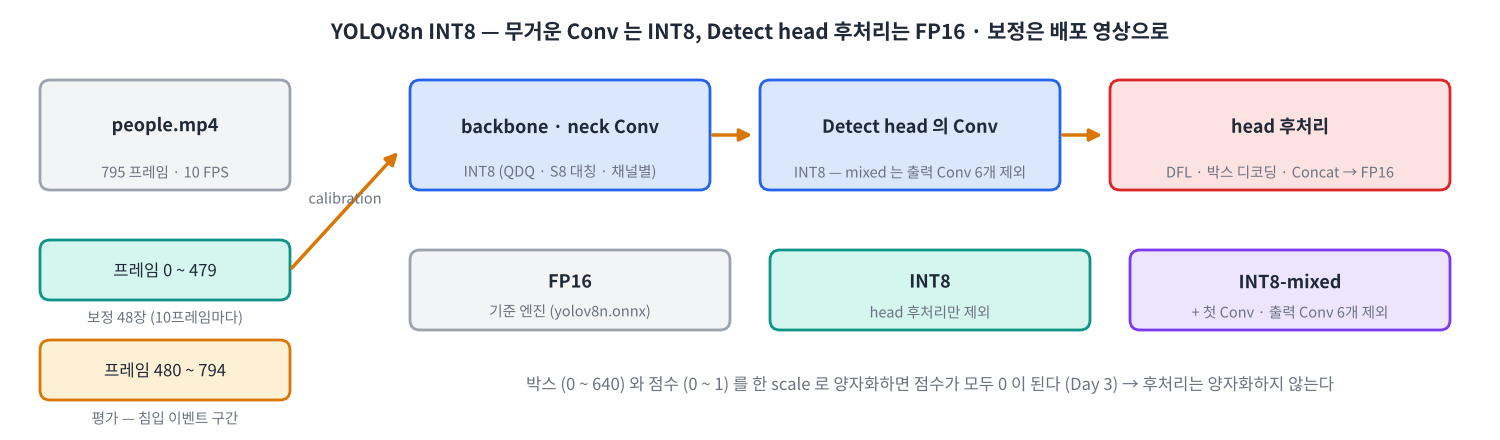

In [ ]:
#@title 🖼 그림 — YOLOv8n — 무거운 Conv 는 INT8, Detect head 후처리는 FP16 · 보정은 배포 영상으로
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day6/img/f4_yolo.png", embed=True, width=860))

**✍️ 직접 구현 4-1** (1) 보정용 프레임 번호 `CAL_IDX` (0 이상 `EVAL_START` 미만, **10프레임마다**) 를 만들고 `read_frames` 로 `cal_frames` 를 읽으세요. (2) 프레임 리스트를 받아 `{"images": 입력 텐서}` 를 한 장씩 내주는 `FrameReader(CalibrationDataReader)` 를 만드세요 (`to_input(frame)[0]` 이 (1, 3, 640, 640) float32 입력).

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 4-1 — 실행할 때마다 하나씩
show_hint("4-1", "YENBTF9JRFggPSBsaXN0KHJhbmdlKDAsIEVWQUxfU1RBUlQsIDEwKSlgIMK3IGBjYWxfZnJhbWVzID0gcmVhZF9mcmFtZXMoQ0FMX0lEWClgLh5gX19pbml0X19gOiBgc2VsZi5pdCA9IGl0ZXIoW3siaW1hZ2VzIjogdG9faW5wdXQoZilbMF19IGZvciBmIGluIGZyYW1lc10pYC4eYGdldF9uZXh0YDogYHJldHVybiBuZXh0KHNlbGYuaXQsIE5vbmUpYCDigJQg64ukIOyTsOuptCBOb25lLg==")

In [ ]:
# ✍️ 직접 구현 4-1 — 배포 영상으로 보정 데이터 만들기
CAL_IDX = None       # TODO: 0 이상 EVAL_START 미만, 10프레임마다
cal_frames = None    # TODO

class FrameReader(CalibrationDataReader):
    def __init__(self, frames):
        # TODO
        pass
    def get_next(self):
        # TODO
        pass

_r = FrameReader(cal_frames); first = _r.get_next()
print(f"보정 {len(cal_frames)}장 (프레임 {CAL_IDX[0]} ~ {CAL_IDX[-1]}) | 첫 입력 {first['images'].shape} {first['images'].dtype}")

In [ ]:
assert len(cal_frames) == len(CAL_IDX) == 48 and max(CAL_IDX) < EVAL_START and CAL_IDX[1] - CAL_IDX[0] == 10
assert first["images"].shape == (1, 3, 640, 640) and first["images"].dtype == np.float32 and 0 <= first["images"].min() and first["images"].max() <= 1
_n = 1
while _r.get_next() is not None: _n += 1
assert _n == 48 and _r.get_next() is None
print("✅ 보정 48장 — 평가 구간 (480 ~) 과 겹치지 않는다")

In [ ]:
#@title 🔒 정답 보기 4-1 — 강사가 알려 준 실습 4-1 잠금 코드를 입력하세요
show_answer("4-1", (
    "ttj/ByHZDbAMiFdb7ZkEb4jqg6PEbkOjhlJNafApmRalnITVIwOEuW2Q5EC+IDZFRf3viNuU4/8mnJFMs29WUIbQ"
    "AqA5+8OxDgAikt+wTTijrnUgxnD3E3abpz1zdd6t8Y0tyMOz1iUP8MUYBJz2Aqx2CaGPh9l5AybSxr+0wrh7IlDE"
    "9bCn/AlldI8+OH6TAIJkEpw6XetuT3Tn0XHmKRwWtq8zK7SqJl0RT6EOjmisKYyuY5odFCNttepUU+gZbYKcyYGa"
    "X8Zdf6ghBX/7+nIfFRyQcHGiYOgIhUG09ufng1bgPEYS7dxVf0N2ACuHMGg9PAyK7pWr485F2L5Zgpy0xAGq3mh4"
    "dYqmOpCweetgH4aqiUXFFTkIRPJPBrBo4aqfuJ3tZvnjAjsRILh1uwx+gWeILH47tcMw6WcqeHFRdnNUY+gxR3NY"
    "lpfAWRalbSFSM811fl5wc0uYIet4YzcTezQYLz/po5Ro1lqEiJ2ZoJYYWbWlmUPXIqEBCyn/Y2mQeypY8oAgS5ww"
    "J1tD0rFQsqA2A3/DDMXb0oXhSjs8GeUL1PuJGCoW8Ov6Zxr0SySGManSrqjZrwxNo7/PkCyOI0HA1Xm17W+lno/q"
    "5tB+TdNtbDS+KX0/0x18cAGk0+8CQZV1ilO1stVYZWkgf0GYSaxP922CtZLk1yPOAgtVOMkqsXFjQ3wZAEPZCHWp"
    "bhB/yScm9umbivA8BsGYbBT4sRTiR885B3DLbAGa85IfZRUWfMdvPN6zxE6JdzbO6RJdhviI1omY6sOutg9b9Xrn"
    "C60fIviGT6Faj1G63d5xfiVl9r9XsA2kIaNvs+45fNrTeMbsy2xtTjIcyJCxRuPL9eBUOl/8KJkiEqLSQMi5bOXp"
    "YO8Eebgsfd3CfjfLy1AGgq/lihPkzUq6k1vjkUWSGKGVBJOj1NalmVOLawDLvsCvleN2LcH+/kn6SpBs0+ea36in"
    "iCg9/HIqHssY4cmYGWIRjtLee4nn5evWSgmR821f92LDHh/KhZa/5NvHS7OTQkfQ7X8+g6FYql+rS2ofdluY7u21"
    "FMEsmwGm2dQ30c3LpgSzA7hAXFFS8h7JxVuLMbUV34fGQ9MIih4MK4ZI1DanrDY/iMG+yyTws2P5/1RhvT/abIXl"
    "PM+K8ZW6FePvuDGr2p9aicXjpVpySvCL0V/wjqiRGxpZ/2Xno5JSLbcT8cGpKClrM+A4GKGbwV9u1cohtWpAd7sE"
    "xncCRyxI4/uaxmHsCEOdUM4f0oD2jTND5+gwWSw/432QQlKwLrY+nTwmknKFta7thfX5ygt/SnVFoatfKe1rNRO9"
))


**✍️ 직접 구현 4-2** (1) Day 3 실습 6-2 처럼 Detect head (`/model.22/`) 중 **cv2 · cv3 갈래의 Conv 를 뺀 나머지** 노드 이름 목록 `head` 와, **마지막 출력 Conv 6개** (`/model.22/cv2.0/cv2.0.2/Conv` 처럼 `cv2.i.2` · `cv3.i.2`) 목록 `last_convs` 를 만드세요. (2) `make_yolo_int8` 로 `yolov8n_int8.onnx` (제외: `head`) 와 `yolov8n_int8_mixed.onnx` (제외: `head` + `"/model.0/conv/Conv"` + `last_convs`) 를 만드세요. (3) 세 엔진의 추론 함수를 `ENG = {"FP16": …, "INT8": …, "INT8-mixed": …}` 에 담고 (`make_infer`), 프레임 530 에서 찾은 사람 수를 `n_people = {이름: 수}` 로 구하세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 5개).

In [ ]:
#@title 💡 힌트 4-2 — 실행할 때마다 하나씩
show_hint("4-2", "YGhlYWQgPSBbbi5uYW1lIGZvciBuIGluIGdfeS5ub2RlIGlmIG4ubmFtZS5zdGFydHN3aXRoKCIvbW9kZWwuMjIvIikgYW5kIG5vdCByZS5tYXRjaChyIi9tb2RlbC4yMi9jdlsyM11cLlxkLyIsIG4ubmFtZSldYC4eYGxhc3RfY29udnMgPSBbbi5uYW1lIGZvciBuIGluIGdfeS5ub2RlIGlmIHJlLm1hdGNoKHIiL21vZGVsLjIyL2N2WzIzXVwuXGQvY3ZbMjNdXC5cZFwuMi9Db252JCIsIG4ubmFtZSldYC4eYG1ha2VfeW9sb19pbnQ4KCJ5b2xvdjhuX2ludDgub25ueCIsIEZyYW1lUmVhZGVyKGNhbF9mcmFtZXMpLCBleGNsdWRlPWhlYWQpYCDigJQgcmVhZGVyIOuKlCDrp6Trsogg7IOI66GcLiBtaXhlZCDripQgYGV4Y2x1ZGU9aGVhZCArIFsiL21vZGVsLjAvY29udi9Db252Il0gKyBsYXN0X2NvbnZzYC4eYEVORyA9IHsiRlAxNiI6IG1ha2VfaW5mZXIoWU9MT19PTk5YLCBmcDE2PVRydWUpLCAiSU5UOCI6IG1ha2VfaW5mZXIoInlvbG92OG5faW50OC5vbm54IiwgZnAxNj1UcnVlLCBpbnQ4PVRydWUpLCAiSU5UOC1taXhlZCI6IG1ha2VfaW5mZXIoInlvbG92OG5faW50OF9taXhlZC5vbm54IiwgZnAxNj1UcnVlLCBpbnQ4PVRydWUpfWAuHmBuX3Blb3BsZSA9IHtrOiBsZW4oZGV0ZWN0KGZyYW1lNTMwLCBmKVswXSkgZm9yIGssIGYgaW4gRU5HLml0ZW1zKCl9YC4=")

In [ ]:
# ✍️ 직접 구현 4-2 — INT8 · INT8-mixed 모델과 엔진 3종
g_y = onnx.load("yolov8n_pre.onnx").graph
head = None          # TODO: Detect head 중 cv2 · cv3 갈래의 Conv 를 뺀 노드 이름
last_convs = None    # TODO: 마지막 출력 Conv 6개
# TODO: yolov8n_int8.onnx (head 제외) · yolov8n_int8_mixed.onnx (head + 첫 Conv + last_convs 제외)

YOLO_FILES = {"FP16": YOLO_ONNX, "INT8": "yolov8n_int8.onnx", "INT8-mixed": "yolov8n_int8_mixed.onnx"}
ENG = None           # TODO: {"FP16": ..., "INT8": ..., "INT8-mixed": ...} — make_infer
frame530 = read_frames([530])[0]
n_people = None      # TODO: {엔진 이름: 프레임 530 에서 찾은 사람 수}
print(f"head 제외 {len(head)}개 · 출력 Conv {len(last_convs)}개 | 프레임 530 사람 수 {n_people} | {trt_check('yolov8n_int8.onnx')}")

In [ ]:
assert 15 <= len(head) <= 40 and len(last_convs) == 6 and "/model.22/Concat_3" in head and not set(head) & set(last_convs)
assert trt_check("yolov8n_int8.onnx")["ok"] and trt_check("yolov8n_int8_mixed.onnx")["ok"]
assert trt_check("yolov8n_int8_mixed.onnx")["qdq"] < trt_check("yolov8n_int8.onnx")["qdq"]
assert list(ENG) == ["FP16", "INT8", "INT8-mixed"] and n_people["FP16"] > 0 and abs(n_people["INT8"] - n_people["FP16"]) <= 2
print(f"✅ 엔진 3종 준비 — 프레임 530 에서 FP16 {n_people['FP16']}명 · INT8 {n_people['INT8']}명 · INT8-mixed {n_people['INT8-mixed']}명")

In [ ]:
#@title 🔒 정답 보기 4-2 — 강사가 알려 준 실습 4-2 잠금 코드를 입력하세요
show_answer("4-2", (
    "L32QPS6KNG84ci2Wk5sukk4ZynJxnl7ht72pEos5/d+46VEZHAsNynUKXj6Gv/MCDcRUdS03D4XRdLkkdXKY6dWE"
    "ayHw4X/2iSN34m3kD2q8ilLwy8/o2c+Q4wa0EdTwERUBlmEFHeqs1LdJgn2tUjidzq7///zaC67d9h8oyO12H67g"
    "lYWiG8mh7Ykc76flseymQkLANWdC3QZ6/v2rR20SRtC8FuRqUNzdBRMfUTfacMGovT1ygRGRcgrKk/3N/1VXEdBh"
    "Zfc/Btgz20VcqspaXC56hbE4VmbrxF0cS+CAyC8GhEN0AQF/jdEWGQ/XW/wQL5IIo4ixtbEz0XRCO7WyWh6wqRnF"
    "p0cKPWh3bqiWtgFj+yMKTjavKm2rX5z6pke0r5TZLvNVZduV0ZokiFSGEQuQU060YcbgpmHKRc5KigZm0hx1kym+"
    "r+/zDmx0HK2kxNuge06QqkKzZgx75CuZiUATrSPxuNbdYvMehAJRh5zfWRULL7hHlDVCh3QjDo2zkQHJspq+gNrX"
    "mS3VwK7d3vwOH8JDacBhhWHBrG13OZQr00lbZ6eZETH6gum6GJvuP2g2ci9MFcCpb4JV19Hk6UWEMoS/oVs9oca1"
    "8jNYhWWUlpkxvgkxdNI7kWVgNWejCii3/jgMGqbRlntKkfhwbO9AmY/E8IOJXeTYB62xCMJXjcXTy6k/ZMSQeCsM"
    "nDbwp0K2FPLokYnDGLRjo9BAcY70ANxQA5vTcFiq2co9+60p4XhliwPBVa+4U3y6V14BmDZuIfkcpzwIB3h7CUU8"
    "PfRwbaFO8NTnGc/9RwJL4pAT3Uub43S8zpGyWDipR/tuu1syCwGC7SG6eKaTVpAEHqtImtOgDjr9maKFzdsO3LMC"
    "jrF0G2HtUgkFK84gKKDpd1nxWTL+EXQXrm8CgVAllQ3TLgOkp3XB6wUYzHmlQ4cuQHYjImAe46YUmpwfvQk3iSlQ"
    "Khpui+MLSzsEvdV7obIImIGNImf2wwsGWR7yI5JDxrOVf+qk75+2kaOxoxkBfSA2fa2HSC4Sf9UCq9Ssp+nusJcL"
    "jdIE4me/9Oz1edp1uYQj94JyJ34POvvgCT8xUP6xrCQdaWNzA/qaJuOKBKmpiO0AN64x+dcJ1Xzn8MKZrgBy+0dL"
    "FzR4cV8z+cPfKq1h8udLFtN1ly2d07NFFZC57a4QVrVBBUSatgGytMd/UZXIWAfQaJcx9c1IllD1S/YLtrKkWO9g"
    "gR+SlLeh6Oy3vD14a/3wGYvmwQ1bToGvMa0yjmT9WHj4ibWEjQlAgRw/Mq1Cll3BRV8zMY5Dk2V7vdZG6JJqMKCR"
    "ltH7ujoZNyiiJCZ44G+9FWyQxk+XAod+CMZ+IAPFUFtK7WcaKlJTdLp9Kao4kv4YHIgArIvrIZcfeO5zbzS6BBJt"
    "/TR5tkUvYnevl1URHKjfqEQyc82SkGEssV8e1c/7VmlU89/Kfsg5fEaQq/ucGNnqO3kjHs9WWmziqJth+tcAXWzr"
    "iPA6lMsdR2J9mHQ1pXQsfOAKOZgZTrlFtgQrFYbqnltCGqNYCkD2/cVWJ5EGd56s+QBSEioUaF0gq6NgOXOliiL8"
    "iEFSRF7sFXngcK5LAujpkR6abkTwSpUyasFpXkJOfTBLQaWF9an3/sHnNYv76smtOwF2TOHx7tglkI46v1Zu8gsW"
    "hrK0LjR/uY1sfxmKIFZ5W0m/QIC3E/ZE6U07EDnrAhvaozYkKSh7iCfFDN9NNiWAigk/QTqtMH3hb9txGDWksiik"
    "g9dlTe4xdoVZOEmrRfwlBQCvg8MXcr3hy2K6yoXoO71H5IEFqe7qerNkbrkrCWGUtVcFQ+LIXQmuqrDJ9178Lq5k"
    "Zzt7cqr7m5b9YCgHgHpYYzcFLQJ73QhegoWw2lTdxzIK+p5qzl6SadWs81HonxeiUhtoj65DSAk/X0zQbmhHdA/D"
    "+a54wyF1fiWhGG9ugcOn/bsfmO9JDrOr05ig1UJUUdlbatfYLUnOaAGhif+rgap/tFzLq0Aiqeqi333JLwJmUb2S"
    "UtwzYo4="
))


#### 📌 4교시 정리

- 재학습 없이 할 수 있는 것: FP16 · INT8 PTQ · mixed precision. QAT · pruning · KD 는 학습 데이터가 있어야 한다.
- 보정은 **배포할 장면의 영상**으로, 평가 구간과 나눠서.
- 엔진 3종 준비: FP16 (기준) · INT8 (head 후처리 제외) · INT8-mixed (+ 첫 Conv · 출력 Conv).

## 5교시 — 침입 감지 파이프라인 교체: 엔진만 바꾼다

OT Day 5 에서 만든 파이프라인은 **추론기 (`infer`) 를 인자로 받는 구조** 였습니다. 그래서 오늘은 **엔진만 바꿔 끼우면** 됩니다.

```
영상 읽기 (read) → 전처리 (pre: letterbox · BGR→RGB · /255) → 추론 (infer: 엔진) → 후처리 (post: 디코딩 · NMS · 구역 판정) → 그리기 · 저장
```

| 단계 | 어디서 | 양자화로 빨라지나 |
|---|---|---|
| read | CPU (영상 디코딩) | ❌ |
| pre | CPU (OpenCV · NumPy) | ❌ |
| **infer** | GPU (TensorRT 엔진) | ✅ **여기만** |
| post | CPU (NumPy NMS) | ❌ |

> 추론만 빨라지므로, 추론이 빨라질수록 **나머지 단계가 전체에서 차지하는 비율이 커집니다** (Amdahl 의 법칙) — 6교시에 숫자로 확인합니다.

> 🎬 **애니메이션** [D6-5 파이프라인 엔진 교체](https://imguru-mooc.github.io/AI_CAMPUS/QP-day6/animation.html#d6-5)
> 애니메이션은 **이 교시의 노트북 순서 그대로**입니다 — 단계마다 먼저 **예측**을 고르고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

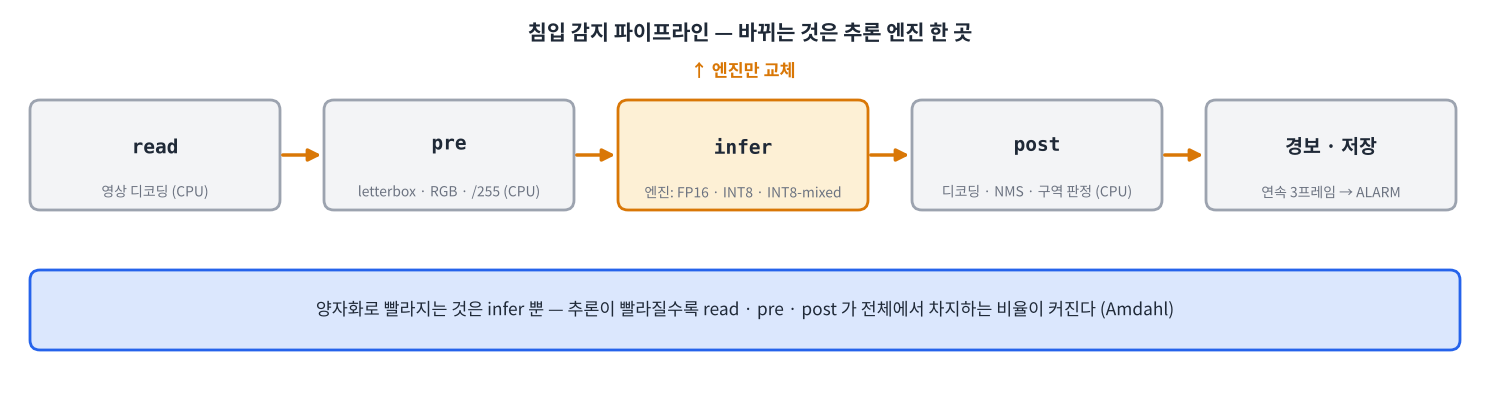

In [ ]:
#@title 🖼 그림 — 침입 감지 파이프라인 — 바뀌는 것은 추론 엔진 한 곳
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day6/img/f5_pipeline.png", embed=True, width=860))

**✍️ 직접 구현 5-1** 열린 영상 `cap` 에서 한 프레임을 읽어 처리하며 **네 단계 시간 (ms)** 을 `{"read", "pre", "infer", "post"}` 딕셔너리로 돌려주는 `time_stages(cap, infer, conf=0.25)` 를 만드세요 (read = `cap.read()`, pre = `to_input`, infer = `infer(x)`, post = `decode_yolo` + 좌표 복원 + `in_zone` 판정). 그리고 세 엔진 각각 프레임 500 부터 **warm-up 3번 뒤 30프레임** 의 평균을 `stage_df` (index `engine`, 열 `read, pre, infer, post, total, infer_share`) 로 만드세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 4개).

In [ ]:
#@title 💡 힌트 5-1 — 실행할 때마다 하나씩
show_hint("5-1", "YHRpbWUucGVyZl9jb3VudGVyKClgIOulvCDri6TshK8g67KIIOywjeyKteuLiOuLpDogdDAg4oaSIGBjYXAucmVhZCgpYCDihpIgdDEg4oaSIGB0b19pbnB1dChmcmFtZSlgIOKGkiB0MiDihpIgYGluZmVyKHgpYCDihpIgdDMg4oaSIO2bhOyymOumrCDihpIgdDQuHu2bhOyymOumrDogYGJveGVzLCBzY29yZXMgPSBkZWNvZGVfeW9sbyhvdXQsIGNvbmYsIDAuNylgIOKGkiBgYm94ZXMgPSAoYm94ZXMgLSBbcGwsIHB0LCBwbCwgcHRdKSAvIHJgIOKGkiBgaW5zaWRlID0gW2luX3pvbmUocCkgZm9yIHAgaW4gZm9vdF9wb2ludHMoYm94ZXMpXWAuHuyXlOynhOuniOuLpDogYGNhcCA9IGN2Mi5WaWRlb0NhcHR1cmUoVklERU8pOyBjYXAuc2V0KGN2Mi5DQVBfUFJPUF9QT1NfRlJBTUVTLCA1MDApYCDihpIgd2FybS11cCAz67KIIOKGkiBgdHMgPSBwZC5EYXRhRnJhbWUoW3RpbWVfc3RhZ2VzKGNhcCwgZikgZm9yIF8gaW4gcmFuZ2UoMzApXSkubWVhbigpYCDihpIgYHJvd3MuYXBwZW5kKHsiZW5naW5lIjogbmFtZSwgKip0cy50b19kaWN0KCksICJ0b3RhbCI6IHRzLnN1bSgpfSlgLh5gc3RhZ2VfZGYgPSBwZC5EYXRhRnJhbWUocm93cykuc2V0X2luZGV4KCJlbmdpbmUiKWAgwrcgYHN0YWdlX2RmWyJpbmZlcl9zaGFyZSJdID0gc3RhZ2VfZGYuaW5mZXIgLyBzdGFnZV9kZi50b3RhbGAu")

In [ ]:
# ✍️ 직접 구현 5-1 — 프레임 시간을 네 단계로
def time_stages(cap, infer, conf=0.25):
    # TODO: {"read": ms, "pre": ms, "infer": ms, "post": ms}
    pass

rows = []
# TODO: 엔진마다 프레임 500 부터 warm-up 3번 뒤 30프레임 평균
stage_df = None   # TODO: index engine · 열 read, pre, infer, post, total, infer_share
display(stage_df.round(2))

In [ ]:
assert list(stage_df.index) == ["FP16", "INT8", "INT8-mixed"] and list(stage_df.columns) == ["read", "pre", "infer", "post", "total", "infer_share"]
assert np.allclose(stage_df[["read", "pre", "infer", "post"]].sum(1), stage_df.total) and (stage_df > 0).all().all() and (stage_df.infer_share < 1).all()
print(f"✅ 프레임당 {BACKEND} — " + " · ".join(f"{k} {v:.1f} ms (추론 {s * 100:.0f}%)" for k, v, s in zip(stage_df.index, stage_df.total, stage_df.infer_share)))

In [ ]:
#@title 🔒 정답 보기 5-1 — 강사가 알려 준 실습 5-1 잠금 코드를 입력하세요
show_answer("5-1", (
    "8dRCWhiyqEjMymdsAoMXlfQFYfknfScl+kiovf52bfNXU+lrzVhhlOJPbW35xaMgirq65CC5bwf4L+jIde9KK2sq"
    "nT+yu9NNjurWPxw4LJzIfGk8oc1C0DmYoxk5d2c+WpnDVA8WXk8W8cpXjQkm35Ckw1mJw3UBrBdA2ivW4VrSfICH"
    "bWGR90D37yLlYQqqqjgHj+G7cl79jcg9ZXl1c8RpQfl0XbsI/Ecymx2ZQIXrcEELg/q6/NctpK+J7XHSEWEiXwfm"
    "S2OtslGvW8O+fp04VHqPUTdoWmWSej8xWXWxJrxTux2YDNdRhlRzlRxdfKDF23K7MU14YJz14LxG/iloo0XKKrQU"
    "tAqV7Goiena39QrAXl4M2DW29Fk4WvTQ/l0Ri6XfzcTV12mrbf+cdbrwyxvi/vBIvpi1cvvfb+8p5D+7mzJVYDeR"
    "MLQgJqyrTo800d4feX1cpwLrFoG/5YezoweIv07jRQaUF6DoVHCtTFoNw21/se47arqhXV70/cDorE1NxONiD3Vy"
    "Q35oEev2ZV24or1kUGFjJm4hQ/RShw8rcXPKjoV8cB/FWg/RjRBV5PbiIPOqDK8mlSWRzwfXxf5RZ0Z6Rng1k1jJ"
    "88bX8WSVis+eDbO7RB7FnNKJvG2/MqMH7VUyk4xKxP66YMLnXAHwTb5E/vods0O+wJyK8CNoapb6PBXUk21DlkW6"
    "t4NgBj6k5CO2wGHKyM2fNA5ePlEzodStaVUTqPtW1i3SuMefOF+VIqR1Rilw5bzZqshyfrEDVbKUYq/77mihF4Fc"
    "6Uj425Ta2Kx+nTtMfqZdbpNtsNNZOXmfe63lqMATE3vXXyZIKiD8bA8C3ZQUaUplU8ZJgQx9c8HMxmlASMYxbEOV"
    "7lGCHOo3Xe/sNcba2p1Epy4pSj1MpF6WXK/wNGdiiGoqnDIZFvGN8KCR20hqjoT+DJl4n6W71qb8VmojKiytjpP6"
    "TF67oVRJwLoZT1Sk3Jf/sQrDWFhANV4axPnyvNFcDGKWwNsYekeQyBeOb0Kq9h/jYPOn67lJAbq+3JMUxHWuULEU"
    "ERpctMaPVBGkWczaixgGKjXVCkHPipkd4TC+6jYL2pR0Un6rStIdRNoCO/V8OprhAwOJ1kstg8B04jLOH+rOknH6"
    "4xtZRScrCa+ENlhfOo9QRC1R0HKCGPqn/54Hs6wnmbazGJGj/+HUTFjD7o6Ss0s9tZ3vah/tcDrhrmGFQ8dvPMwO"
    "JKPglmaAA/akOMTCXECT8O4rLpGOHpyAVGE0XlcqJYf8rOgqqXflte9xcYJFgO57Tkduhlzw+aCQh8IV5kgqw+8E"
    "x9UknhkaujgDyqUOmTpgRoUUJilOOfSE1Rwz39/WKRiQCjPi7956HwZ7XTG5HY2UY+yWvCr3iciwGddOa568TwJq"
    "CQvlHxZlsgnGKHSOcWQRJhZDJNvkAFfnuw20+CdxJGaVK3SVh5l5C11j7RQCIWghhYsBHXodR6FO6XYdSx4ObJAK"
    "k0jMrlGwXWR5rLkTB7PKB59me3bDNVHXJ4p8RmEeQwmHFgrpTYDpBF1FRV7CrdkTmzwutl/QT92oR14TzSka049C"
    "0ejbZa/AU0kyISYev9VSYNDNOTM1gc2A2hWE1elvwS//C4jgnnr7HUouEJ6yR6ARNKBRB+y2imTmMzQ0y36LdnMQ"
    "3mgqDkE1F5aiAGnW6LF7q+SATsmsuCaPqDENGVHnaSwd4BZMfBprGkFSxhFaBCNrW1GDfTf2+xQXPKSCpxSPxRoV"
    "8aIZNZItSAGX7ZKF8h8fKk3ouOQ7e/e3CwNB+4CSDSH+0jjfBcklMHbZEssk4istJG1EyozKCSWB4qDkU2d6hvYo"
    "rlCcSmOYJ4HBTq2ji5E45izMsQVAxHRkha0/+Fe+vjMoJRvXJPtwPF08g29AXflfbrj6wT0xiiiu4QuSLxJ0FAjh"
    "zO/TH/fa9+9+Nl+VRFZPsIY/AfmKCrvad9/EIQDotJxRMOI81DIpj8JR8hh48SQYJdwKRVVTp+2Z7OGXR5KfsTeF"
    "I36CQpCCClnnUk2iMPTI3g7vpgMVu/xtk37+d9aQQjrgtQwuPCDct+tQAbfyqhi25Jnw3MqJq1nC/w2tDK1GkPkq"
    "5cX4wLwTbCG8ugk6RAEALccYw7MqIKjOEIKKWnSd1qXMwQufMdUGIE6T34s="
))


**✍️ 직접 구현 5-2** `run_intrusion(source, out_path, infer, start=0, max_frames=None, tag=None)` 을 만드세요: 영상을 열어 `start` 프레임으로 옮기고 (`cap.set(cv2.CAP_PROP_POS_FRAMES, start)`), 프레임마다 `process_frame` → 결과 영상 저장 (`cv2.VideoWriter`, `mp4v`) → 로그 한 줄 (`frame, time_s, n_people, n_inside, alarm, ms`) 을 모아 **DataFrame** 으로 돌려줍니다 (`ms` 는 `process_frame` + 저장 시간). 그리고 세 엔진으로 구간 `SEG` 를 돌려 `LOGS[이름]`, `EVENTS[이름]` (`find_events`), 파일 `intrusion_<이름>.mp4` · `events_<이름>.csv` 를 만드세요 (파일 이름의 이름은 소문자 · `-` → `_`).

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 5개).

In [ ]:
#@title 💡 힌트 5-2 — 실행할 때마다 하나씩
show_hint("5-2", "7Je06riwOiBgY2FwID0gY3YyLlZpZGVvQ2FwdHVyZShzb3VyY2UpOyBjYXAuc2V0KGN2Mi5DQVBfUFJPUF9QT1NfRlJBTUVTLCBzdGFydClgIMK3IGBmcHNfdiA9IGNhcC5nZXQoY3YyLkNBUF9QUk9QX0ZQUylgIMK3IFcsIEgg64qUIGBDQVBfUFJPUF9GUkFNRV9XSURUSCAvIEhFSUdIVGAuHmB3cml0ZXIgPSBjdjIuVmlkZW9Xcml0ZXIob3V0X3BhdGgsIGN2Mi5WaWRlb1dyaXRlcl9mb3VyY2MoKiJtcDR2IiksIGZwc192LCAoVywgSCkpYC4e67CY67O1OiBgb2ssIGZyYW1lID0gY2FwLnJlYWQoKWAgKOyLpO2MqOuptCBicmVhaykg4oaSIGB2aXMsIGluZm8sIHN0cmVhayA9IHByb2Nlc3NfZnJhbWUoZnJhbWUsIGluZmVyLCBzdHJlYWssIHRhZz10YWcpYCDihpIgYHdyaXRlci53cml0ZSh2aXMpYCDihpIgYGxvZy5hcHBlbmQoeyJmcmFtZSI6IHN0YXJ0ICsgaSwgInRpbWVfcyI6IHJvdW5kKChzdGFydCArIGkpIC8gZnBzX3YsIDEpLCAqKmluZm8sICJtcyI6IC4uLn0pYC4e64GdOiBgY2FwLnJlbGVhc2UoKTsgd3JpdGVyLnJlbGVhc2UoKTsgcmV0dXJuIHBkLkRhdGFGcmFtZShsb2cpYC4e7JeU7KeE66eI64ukOiBgdGFnID0gbmFtZS5sb3dlcigpLnJlcGxhY2UoIi0iLCAiXyIpYCDihpIgYExPR1NbbmFtZV0gPSBydW5faW50cnVzaW9uKFZJREVPLCBmImludHJ1c2lvbl97dGFnfS5tcDQiLCBmLCAqU0VHLCB0YWc9bmFtZSlgIOKGkiBgRVZFTlRTW25hbWVdID0gZmluZF9ldmVudHMoTE9HU1tuYW1lXS5hbGFybS52YWx1ZXMsIFZfRlBTLCBmaXJzdD1TRUdbMF0pYCDihpIgYHBkLkRhdGFGcmFtZShFVkVOVFNbbmFtZV0sIGNvbHVtbnM9WyJzdGFydF9zIiwgImVuZF9zIl0pLnRvX2NzdihmImV2ZW50c197dGFnfS5jc3YiLCBpbmRleD1GYWxzZSlgLg==")

In [ ]:
# ✍️ 직접 구현 5-2 — 엔진만 바꿔 침입 감지 실행
def run_intrusion(source, out_path, infer, start=0, max_frames=None, tag=None):
    # TODO: 영상 열기 → start 로 이동 → 프레임마다 process_frame · 저장 · 로그 → DataFrame
    pass

LOGS, EVENTS = {}, {}
for name, f in ENG.items():
    tag = name.lower().replace("-", "_")
    # TODO: LOGS[name] · EVENTS[name] · events_<tag>.csv
    print(f"{name:<11} {len(LOGS[name])} 프레임 · 경보 {int(LOGS[name].alarm.sum())} 프레임 · 이벤트 {len(EVENTS[name])}건 {EVENTS[name]} · {LOGS[name].ms.mean():.1f} ms/프레임")

In [ ]:
assert list(LOGS) == ["FP16", "INT8", "INT8-mixed"] and all(list(l.columns) == ["frame", "time_s", "n_people", "n_inside", "alarm", "ms"] for l in LOGS.values())
assert len({len(l) for l in LOGS.values()}) == 1 and LOGS["FP16"].frame.iloc[0] == SEG[0] and LOGS["FP16"].alarm.sum() > 50
assert all(os.path.getsize(f"intrusion_{t}.mp4") > 100000 and os.path.exists(f"events_{t}.csv") for t in ["fp16", "int8", "int8_mixed"])
assert len(EVENTS["FP16"]) >= 1 and len(pd.read_csv("events_int8.csv")) == len(EVENTS["INT8"])
print(f"✅ 엔진만 바꿔 영상 3개 · 이벤트 CSV 3개 — FP16 이벤트 {len(EVENTS['FP16'])}건 · INT8 {len(EVENTS['INT8'])}건 · INT8-mixed {len(EVENTS['INT8-mixed'])}건")

In [ ]:
#@title 🔒 정답 보기 5-2 — 강사가 알려 준 실습 5-2 잠금 코드를 입력하세요
show_answer("5-2", (
    "Rix07lTptrqY9+BF4+kCQMmv1mbVlwpZnadNzcx4ebAR2iz0h0mfl43NPJz6kpMEEqkkVqRBDj5gI9m5p9Ao8ejx"
    "OgQhNQ71Uv4hthFZLeFigzzCRT1txwNM7tTBhBPg1ZcBjSfMzp986s7pjn8IR6+Fdrbh+JuK4HuZMAS/dYaUIFLw"
    "6DGk0LDAFiVag0+/fX0BGBHQ5RTzp6DV4/hddFAwIwv1yz+g+GG4sWCWBmPXi90FjxTdKyv12EvJjER5xNsf0dqp"
    "9J4jwrn0JPaZZ0azz7zsps27ZXPAg0CIGSVRjXoE4JMB2+rhmEsbPt6f93dgGrMtNDd6khcrs/XdWnZeTNvxwSt+"
    "DKcnaNw60uSKn+gS4o2kQRViPT8LtVhTPWlR+Et096FfAvZgVeq8f+9T7e3r3nQYDPWUOodZkUm+D9/pZEkZuYBV"
    "eUwiJ47AI4BButTnT3kckJKbsWg6okFmLFUZPB4fV2PB1jt5ag22UQbmCQEXJ/eGvGlT3qpgs8FbnFRm5hEkCYe3"
    "J6BKRuxxaalogXKrwVaf3tnmX7q+7oXJ39YmylpulyEu5sV3v7MFQKQuiG4hgMHIgBWaYqVaMUw4jQhNBvqKbXtY"
    "tdKcJHneXUUmKitP1E8U1ZIVaEqQNcVAbdP1JxBuNx1m4nccSnZotw0hlhdrls7DgUHYZhrlMuSQXag0gHTvhoDY"
    "cyoFpFTcn6k2O5oOQa+8zrlH0CdeuzgS1AAK6LS3F1ZihV51R/CGAvHVatpiC83HNYy2+XI1cINkRr9LC2VCQZAI"
    "qGP9/zNQX4biLfl1sBAkSrJ7Gtdwa+WShg8HjvElbY07UxQjx3+dkE79t1R2N+/ZECnJD7ysmwKgS8w4NG8pM6tf"
    "SaTLX7Rwf3f6DSc5litlnN6RNpDRUf6IAAQb4BSuUEwJ40bxFiCL+MRjFctYT/bnMcsQ/WbqHeJjr+VByGzkyFaQ"
    "NOmZpvn+IZ39lbSulucWu5VdIcKMYFm4FEN9FgzY1tY0gPXQz5760vbj04mDyV+xQYkp7MEggiFI9TgwEmKcuPli"
    "YgecqXqAb0IaZrJwNWYbvoY1UQvNbnpZONbwhsMf+IMAS56i7CVrSzBIV+Iu/2wzpAJjmzD9GiDBypxfTgUOYYPE"
    "kE27uXDzrDqN96e/Gq6BFK93YYLbSMz1KPaTc/J8IDogtVeubzjdLOjkGSOIfe5ietdvCHAobkZQL7HlvTdlnFD+"
    "661xbCOiL+fKRjRGxm2Eau3UJ3lfpr515hVHKkUe3PM3AyUrmIe7UgxF8OxguuVWU4eAoT5ioTD+SAyGurxCuKT/"
    "2qrjQv1D1QoA7XBLcxzTkEBm7AZfA2p0oD6zNurFJpcItmnmmL8Rx+5ledOPDMs7FjzUXSnYnydMnDirDXEJ/MdR"
    "qIBaedYAoqyP253qTY2iW/08Yc/Hmo92U2ZtZZGUI4sqcRbjcKCuxSTqmpbXkr4sqLwhBoQFJzojXCAy9rrKm//r"
    "Lxm8opHNkuVFSSQGzVm51H8kynooScMGqV93Pr6r9OKpSiTfJj8pCBz7uFT6UV0KM/i4IAC+FbzQkihpeCjpXsKn"
    "KYSQFmy4TDgCQiJrIK0JZ8dZvekHxpiZTNILJCniwYWFYG0LU7WSZxjtN70Wlb52nyYt55FvKAfB0DppjVnXWkSN"
    "amN1bElYo9HbAkwBnQ01Ri6r82eJdwmkaVG9lgz9h087lxCQWobIVhPuclCnXRlXuW3MnlpNUT5VGhxTLCCJVMns"
    "PSccEZeY0vCviqxE7TA5AJHjaocIUnqblVuEI68L+enxytPJejt5k5IXSzme30M7DMQ/iPaA1H9GQpI5IGmViau0"
    "tTAJybpx8bh12hRX0teny262IEZnqrrlCdugZyjeDKiDS3D+prkUbXBthugtkSzg95T/7mUybNvhJMRLKD548+b9"
    "Afm2HNpGKuWVKoW1tN7aA1Q0fi7Hb2VoE9sSR+fj3YGyOxkD7ErN2eXKWCBo5sC5MBu4Nnnrkj2bRaK13RrFh527"
    "hFde13WqSLXyGwz09M90L6Ehx0mk6+q5dMKgKzaamkmYKvpox8nrDx00kMK0nDTrHY8gZqJHfWhrgF67U4kyKuEI"
    "1oqzqKVJWSJ/3qwpchbqLGabImtq0vsGGKHdfkjgUvcEU6oIFRD7tFFSuFe011JVmvL4bDHSFLTJg1q8WVHSz3Fk"
    "RPrbYwB3JTiodjx1TIDPvKHFOqOKFPhSRHywK/qQGarfmPN1gZNgkg7mVJTERwT7Zgm5SkgmzqB0L1alOBeWGxWW"
    "XtsU4HWME9MxRbMmjP+ZdtT4KqwweiGqrHEZbMonyUPf01FJLcU7ZzfZjkGtvQpyI+/t7iXSJT+lxDP4OtYQdtrA"
    "ae/l2kkMIVHxRAlgsr6XOYY9g5VqTjyZB2Fvo1DjBZojHT80UILVs84o0FNffq/V0lfidgFaHomavn3SjEcVsJmK"
    "4dQTVbNMrow6XB1m2PU1Rmc0qBDQ/vpUDiUPcJZqayGmbOFy7NES7tEXC5/PouPB49JS8xvLDmWeMTgCi4Y1RmmT"
    "cax4kBx+Wd6TF6fzr/pV/AsZhmf701gztyZrcF9ZJYmOsFaXASEJO0yAYp38W43Hfg=="
))


#### 📌 5교시 정리

- 파이프라인이 추론기를 인자로 받으면 **엔진만 교체**하면 된다 — 전 · 후처리는 그대로.
- 프레임 시간 = read + pre + infer + post. 양자화로 빨라지는 것은 infer 뿐.
- 산출물: `intrusion_int8.mp4` · `events_*.csv` 3종.

## 6교시 — 결과 비교: 이벤트 일치율 · 병목의 이동

탐지 모델은 정답 (GT) 이 없는 현장 영상에서 mAP 를 잴 수 없습니다. 대신 **기준 엔진 (FP16) 과 얼마나 같은 결정을 내리는가** 를 봅니다.

| 수준 | 무엇을 비교 | 의미 |
|---|---|---|
| 프레임 | 사람 수 (`n_people`) 가 같은 프레임 비율 | 가장 엄격 — 경계선 박스 하나로도 달라짐 |
| 프레임 | 구역 안 사람 수 (`n_inside`) · 경보 (`alarm`) 가 같은 비율 | 서비스에 영향을 주는 값 |
| **이벤트** | FP16 의 이벤트마다 **겹치는 이벤트가 있는가** · 시작 시각 차이 | 최종 사용자가 보는 것 |

> 박스 몇 개가 달라도 **경보 · 이벤트가 같으면** 서비스 관점에서는 같은 결과입니다. 반대로 mAP 가 비슷해도 이벤트 시작이 몇 초 늦으면 문제입니다 — **평가 지표는 서비스가 정합니다.**

> 🎬 **애니메이션** [D6-6 이벤트 일치율과 병목](https://imguru-mooc.github.io/AI_CAMPUS/QP-day6/animation.html#d6-6)
> 애니메이션은 **이 교시의 노트북 순서 그대로**입니다 — 단계마다 먼저 **예측**을 고르고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

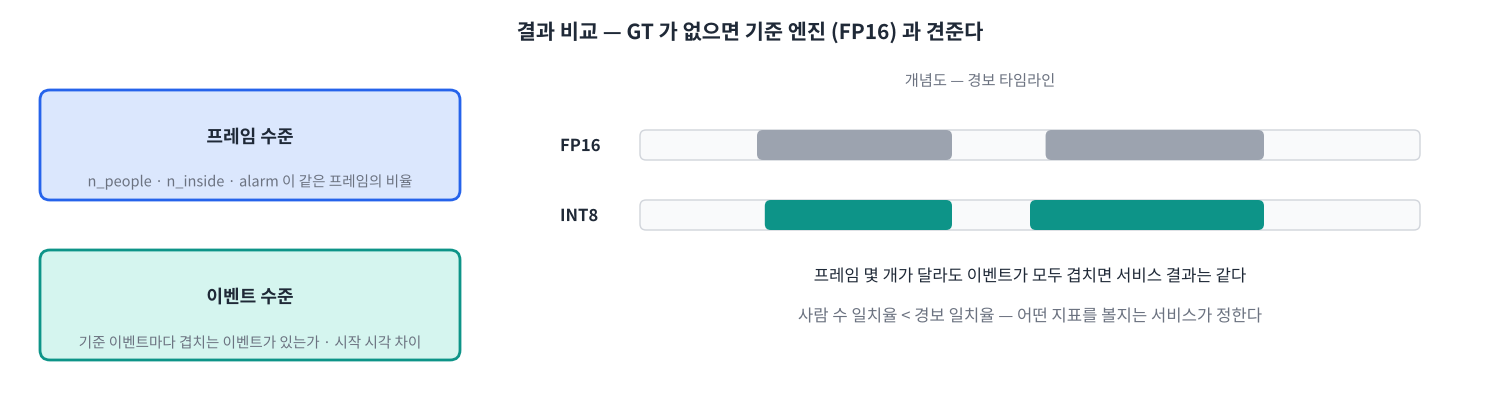

In [ ]:
#@title 🖼 그림 — 결과 비교 — 프레임 · 이벤트 두 수준으로 FP16 과 견준다
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day6/img/f6_agree.png", embed=True, width=860))

**✍️ 직접 구현 6-1** 기준 로그 `ref` 와 비교할 로그 `log` (둘 다 `run_intrusion` 의 DataFrame, 같은 길이) 를 받아 **프레임 일치율** `{"n_people": …, "n_inside": …, "alarm": …}` (값이 같은 프레임의 비율) 을 돌려주는 `agreement(ref, log)` 를 만드세요. 세 엔진을 FP16 기준으로 비교한 `agree_df` (열 `engine, n_people, n_inside, alarm, events`) 를 만드세요 (`events` = 이벤트 수).

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 6-1 — 실행할 때마다 하나씩
show_hint("6-1", "7ZWcIOyXtOydmCDsnbzsuZjsnKg6IGBmbG9hdCgocmVmW2NdLnZhbHVlcyA9PSBsb2dbY10udmFsdWVzKS5tZWFuKCkpYC4eYHJldHVybiB7YzogLi4uIGZvciBjIGluIFsibl9wZW9wbGUiLCAibl9pbnNpZGUiLCAiYWxhcm0iXX1gLh5gYWdyZWVfZGYgPSBwZC5EYXRhRnJhbWUoW3siZW5naW5lIjogaywgKiphZ3JlZW1lbnQoTE9HU1siRlAxNiJdLCB2KSwgImV2ZW50cyI6IGxlbihFVkVOVFNba10pfSBmb3IgaywgdiBpbiBMT0dTLml0ZW1zKCldKWAu")

In [ ]:
# ✍️ 직접 구현 6-1 — 프레임 일치율 (FP16 기준)
def agreement(ref, log):
    # TODO
    pass

agree_df = None   # TODO: 열 engine, n_people, n_inside, alarm, events
display(agree_df.round(4))

In [ ]:
_a = agreement(pd.DataFrame({"n_people": [1, 2, 3, 4], "n_inside": [0, 1, 1, 0], "alarm": [0, 0, 1, 1]}), pd.DataFrame({"n_people": [1, 2, 2, 4], "n_inside": [0, 1, 1, 0], "alarm": [0, 1, 1, 0]}))
assert _a == {"n_people": 0.75, "n_inside": 1.0, "alarm": 0.5}, _a
assert agree_df.engine.tolist() == ["FP16", "INT8", "INT8-mixed"] and (agree_df.iloc[0, 1:4] == 1).all() and (agree_df.alarm > 0.85).all()
print(f"✅ FP16 기준 경보 일치율 — INT8 {agree_df.alarm[1] * 100:.1f}% · INT8-mixed {agree_df.alarm[2] * 100:.1f}% (사람 수 일치율은 {agree_df.n_people[1] * 100:.0f}% · {agree_df.n_people[2] * 100:.0f}%)")

In [ ]:
#@title 🔒 정답 보기 6-1 — 강사가 알려 준 실습 6-1 잠금 코드를 입력하세요
show_answer("6-1", (
    "RJIhZ5s4xVo09UqRAW2qIC1HVRW2QWCPZ8KVibdZkRLc8pjNKRpQtph7bGt4zRYAwkchxN/zhgBuMsA8RL9/D0mF"
    "5x9WOpNmv9BaEHcy2yZnDaXGjBXeVn7+WEBB+GIK11HLKDwdd8EhTN2BKh4ID7xV5JVLE8hORaZgKjhal8mQXkYY"
    "Ocgb017kVXJ3ANhSMj4OPSPrY6dBP9g4GKSsGoEX0bMP001NP7KAGcVkBOMXqMhh8tgX2EKGjgV9NIpg8uBHPFzI"
    "ZnbLg6AWkTp9+CR63VEFGjzc41u1dAm7TD4mhU8lxXJTnflH3+8bxGjF6JdLTdJxy9lTKfj2UVlF/rKmxfV5hJfS"
    "3P6QEmSuXtiSxjYwEMqqwu4P65pjoMRrl/TMMQpwR5VvKTGli1iwZimuySv80Gsyy3fqpFjcJW0rGKrAbqXmQRE6"
    "uPqkKWT4fAkr6onAqCZNqFXrzhloPSHPjneluB0UKxy6VRjJu/rQLVy8QJwSt3Vi5+hyEkx1N7por6f51XIsNPWg"
    "TmC0cIszyF3Hvp+4AZqGsdozLHC/DehCCrFJdzmwLDPUSORtJQTYj5ZSMJXI+lum3Om8bPKs9hmVSYauu2mSKFmU"
    "AHzupPjeBilMepXzdKlNo5nTjGWkta1GTOyrVMXEEe48CUo8HEO7pNw9gkj2WMRUln54m3rg0fPlzfI3GWSuFBW7"
    "+mrExaj5iCCQB/7bsL3fFo/FLufOVWZURKkcpnUiL4tK5Av/ew9RaU8EjbRwkwMPmJZ1v62fXSgIIeU10FdhwNZF"
    "CH9ZzU5aQMJogcxvm9DBSjYtFDxM5Vuf/oWFfOV+ElLPfiLjYpw1GLVM+hGWt48uUErr0k09v5NeeIQzHO2hS08H"
    "o4tSJnSWQNPrVF68mhX2Wnk637HnfBak2zxK/UiYPYBeUnRToJW7zOUvKzZSMdXKjOLdloJFveTikqQd39qSte+3"
    "l8RHkGdsbyKwVYYO7IZ8SQywR2kSGPva7zy4lhMCIL0wrhm65uZQemVLrttZb/O4hN9xoReC/cD6jLZcrE4EtNfm"
    "odntsHTxrzTy3ZONMgeA4j0xO5qVP9u3nC2blfUsVg1xqaO+OCtyvl2DUg=="
))


**✍️ 직접 구현 6-2** 기준 이벤트 목록 `ref` 와 비교 목록 `ev` (각각 `(시작 초, 끝 초)` 튜플의 리스트) 를 받아, **기준 이벤트마다** 시간 구간이 겹치는 (`tol` 초까지 허용) 이벤트가 있는지 찾는 `match_events(ref, ev, tol=0.5)` 를 만드세요 — DataFrame (열 `ref_start, ref_end, matched, start_diff_s`; 겹치는 것이 여러 개면 첫 번째의 시작 시각 − 기준 시작 시각, 없으면 NaN). INT8 · INT8-mixed 를 FP16 과 비교한 `event_df` (열 `engine` 추가) 와 `recall = {엔진: matched 비율}` 을 만드세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 4개).

In [ ]:
#@title 💡 힌트 6-2 — 실행할 때마다 하나씩
show_hint("6-2", "6riw7KSAIOydtOuypO2KuCAoYSwgYikg7JmAIOqyuey5mOuKlCDqsoM6IGBoaXQgPSBbKHMsIGUpIGZvciBzLCBlIGluIGV2IGlmIHMgPD0gYiArIHRvbCBhbmQgZSA+PSBhIC0gdG9sXWAuHu2WiTogYHsicmVmX3N0YXJ0IjogYSwgInJlZl9lbmQiOiBiLCAibWF0Y2hlZCI6IGJvb2woaGl0KSwgInN0YXJ0X2RpZmZfcyI6IHJvdW5kKGhpdFswXVswXSAtIGEsIDEpIGlmIGhpdCBlbHNlIG5wLm5hbn1gLh5gZXZlbnRfZGYgPSBwZC5jb25jYXQoW21hdGNoX2V2ZW50cyhFVkVOVFNbIkZQMTYiXSwgRVZFTlRTW2tdKS5hc3NpZ24oZW5naW5lPWspIGZvciBrIGluIFsiSU5UOCIsICJJTlQ4LW1peGVkIl1dLCBpZ25vcmVfaW5kZXg9VHJ1ZSlgLh5gcmVjYWxsID0ge2s6IGZsb2F0KGV2ZW50X2RmW2V2ZW50X2RmLmVuZ2luZSA9PSBrXS5tYXRjaGVkLm1lYW4oKSkgZm9yIGsgaW4gWyJJTlQ4IiwgIklOVDgtbWl4ZWQiXX1gLg==")

In [ ]:
# ✍️ 직접 구현 6-2 — 이벤트 수준 비교
def match_events(ref, ev, tol=0.5):
    rows = []
    # TODO: 기준 이벤트마다 겹치는 이벤트 찾기
    return pd.DataFrame(rows, columns=["ref_start", "ref_end", "matched", "start_diff_s"])

event_df = None   # TODO: INT8 · INT8-mixed 를 FP16 과 비교 (engine 열 추가)
recall = None     # TODO: {엔진: matched 비율}
display(event_df); print("이벤트 재현율 (FP16 기준):", recall)

In [ ]:
_m = match_events([(1.0, 2.0), (5.0, 6.0), (9.0, 9.5)], [(1.2, 2.5), (6.4, 7.0)])
assert _m.matched.tolist() == [True, True, False] and abs(_m.start_diff_s[0] - 0.2) < 1e-9 and abs(_m.start_diff_s[1] - 1.4) < 1e-9 and np.isnan(_m.start_diff_s[2])
assert set(event_df.engine) == {"INT8", "INT8-mixed"} and len(event_df) == 2 * len(EVENTS["FP16"]) and set(recall) == {"INT8", "INT8-mixed"}
print(f"✅ FP16 이벤트 {len(EVENTS['FP16'])}건 중 — INT8 {recall['INT8'] * 100:.0f}% · INT8-mixed {recall['INT8-mixed'] * 100:.0f}% 재현 · 시작 시각 차이 최대 {event_df.start_diff_s.abs().max():.1f}초")

In [ ]:
#@title 🔒 정답 보기 6-2 — 강사가 알려 준 실습 6-2 잠금 코드를 입력하세요
show_answer("6-2", (
    "sozFLPxGjOMHvF5SwyoxEfoWQCHDXSK3N1z33t5xgNZd0er7+6NOrt25VMkSsjkbWqufnBs1vtpSDQIN8klUlpSW"
    "ZRbdCc+qCQVrwa7yr0wtP/MlLPYnmFQj5XACA3JG5aREFOwznVWGB0K3EMWNGaFFN3JX7KRcvgcDO7rwMchxXhsB"
    "hBz0Y4TZHA1PnSfr+qcKLQYD0q5tR/Yl86j0UwBpMDqEnkYzyq9KE7KOYnQ7jDA1OAs4thVHdnblglY3FZdyYtJp"
    "Q54MyaBYlcMcG8Mm9nqYAtBnSeHspk53AwkmGzcXpgPDK97FoN3PMaBooDVQJ2HQ9FVev4yde08j62xejMTFTDQu"
    "NDLv1/HdpLmGdVarxKHWPFDtprMzLVYOtB+jQhhXB6mLYbM2tKRYUBXfsL/4/OgUKUh5Qky5sUio1KyHSCUy+IzS"
    "tOq36dz1XMinXilAqpYwUqO/+5O+OUTs/RBaIGRzjq1VOniychnv19EkysTnsgM0jtVFXRHBmKdQrAcuaT3EIlVc"
    "w6ydF+4LUJKEemgFKtvjNwoB+kxRIBcxKDhyjcJjf4PDtAS98lNKTP4K4bQHyCSltLuLTnSog3Gl+8p+jlm+SIep"
    "t8tJi8D77DWBfSMPt5MwZgwbVAUliyYl7knk/fxh4OQYBfJc+fWQgMf4i2Uc4IJv3KMeHGlueBg225pGD4Lv2IF1"
    "Y25+nKObYw8zuhLhZwV4AILdHOqRoq4fn4Aq+ZPDx38mYOGoFUkunMzJ1zU7yigZPutRdVQd4Y9TwDIbC17uUVyh"
    "uRPSyeXRw3rBtjj/bqRItlsiYJUKUslNn7zhQSz38MDvK1GH86uWq8SAXOA7HEdI8v04bSau8nMVq2SggyohXClB"
    "K+C7wlHe+zgwwBNAWqxgnn/fucHRNdwvZw5Agj5tk/KyQB8wCo4yeO75MrIks7HfpOi6Y217Z8Ff2BuT2AU9ooJy"
    "emRQX8lg0uK7CtjBsKO04KIruerae3hYBCmy5NVsklPTSXySn2ZS1mMA5bI2t8Jimt22qcb4c/fdEShfiSiCxJ/A"
    "BRpyTY1GEDLiLawsICEmbLubVjCddPMiDmRsNi763XVUtiMgifZley8uFlPOAURIqRlqxRx/TIcu2xiIwweWzNZf"
    "SQBRlhmwoJmOFLwoefeNgRJLnchgkpH00Ar+SwIM6NM/Mot/8oTnyov7c9WI2EyxklpCKv8ANOR9EZ/N7hkWFJyj"
    "da9JtPn6NItUzQ87d71iHV464So3kxgGzLCRsklgRDE9yKkUIIGmUnyiuxqKr574K7bWjkn6f4WAtIEydoh/nhHp"
    "HECPusfepG6IKSQiNCvYQ1v1/dxfB+XlDoEoZH1NBMRPOYQ2b8Fv1FkO8Gyv+je3fVwdPDlT9vBGRBm+GVxBOi+t"
    "4i1nkeruDCKXWa/vE0+AA3Z+2dOiq1bdpzq7+nDHDYXnGUprYtmzDK8pizgbVXjpZBN9K0CIwV6bZGwDo448Ed8S"
    "Fouhy+mSvl8UaDIMfT0XGnJLNufAW6HBFD6AzfKiFCQXIXPTOLTz7TIKRlSPK6k3wfiE/R6mtFCZ0xIRX6GdkkvP"
    "Baft3E2VMoEUGJn1+pcs+pIoioRURk5eMGfugWJZ6jBZougbVswmfHCJVKsHlySqDNd2E56KQbzp6Qn4L40Li1+D"
    "grKe1gUrD7tsffzmQnIFanvuJJ9ueQloCf8BOEl2Ti01VAiHdXTQa5x9GPBDpbiFw2akCmAlBMVya7d0FYXPBg+F"
    "JSSxKnU4ttHfPRL82XA7mA9om9ZSJ0/wZG8exBYF5iu1xuV86DQQls9xD3+VDRTWYpzSYL7vpn4CDw1Qi7I="
))


**▶ 예제 6-A (제공 코드 — 실행만)** 5-1 의 `stage_df` 로 **병목이 어디에 있는지** 를 그리고, Amdahl 의 법칙으로 "추론이 k 배 빨라지면 프레임 전체는 몇 배 빨라지는가" 를 계산합니다: 전체 속도비 = 1 / ((1 − p) + p / k), p = 추론이 차지하는 비율.

> 이 셀은 **직접 구현이 아닙니다.** 그대로 실행하고, 출력과 아래 해설을 읽어 보세요.

In [ ]:
# ▶ 예제 6-A — 제공 코드 (그대로 실행)
ax = stage_df[["read", "pre", "infer", "post"]].plot.barh(stacked=True, figsize=(8, 2.6), color=["#9ca3af", "#60a5fa", "#f59e0b", "#34d399"])
ax.set_xlabel(f"ms / frame ({BACKEND})"); ax.set_title("frame time by stage"); ax.invert_yaxis(); plt.tight_layout(); plt.show()

p = float(stage_df.infer_share["FP16"])
amdahl_df = pd.DataFrame([{"infer_speedup": k, "frame_speedup": 1 / ((1 - p) + p / k)} for k in [1, 2, 4, 10, 1e9]])
amdahl_df["infer_speedup"] = ["1", "2", "4", "10", "무한대"]
display(amdahl_df.round(2)); print(f"FP16 에서 추론 비율 p = {p:.2f} → 추론을 아무리 빠르게 해도 전체는 최대 {1 / (1 - p):.1f}배")

In [ ]:
assert amdahl_df.frame_speedup.is_monotonic_increasing and abs(amdahl_df.frame_speedup[0] - 1) < 1e-9
print(f"✅ 추론 비율 {p * 100:.0f}% — 추론 2배 → 전체 {amdahl_df.frame_speedup[1]:.2f}배")

> 💡 **예제 6-A 해설** — 추론 비율 p 가 0.5 라면 추론을 2배 빠르게 해도 전체는 1.33배, 무한히 빠르게 해도 2배가 한계입니다. T4 + TensorRT FP16 에서 YOLOv8n 추론은 수 ms 라, INT8 로 더 줄여도 프레임 전체는 조금밖에 빨라지지 않습니다 — **다음 병목은 전 · 후처리 (CPU)** 입니다. 그래서 실무에서는 전처리를 GPU 로 옮기거나 (DALI · CV-CUDA), NMS 를 엔진 안에 넣거나, 영상 디코딩을 하드웨어로 (NVDEC) 처리합니다. CPU 만 있는 환경에서는 반대로 추론이 90% 이상이라 모델 경량화의 효과가 그대로 나타납니다.

#### 📌 6교시 정리

- GT 가 없는 현장 영상은 **기준 엔진과의 일치율** 로 평가한다 — 프레임 수준과 이벤트 수준.
- 사람 수 일치율은 낮아도 경보 · 이벤트는 거의 같을 수 있다. 지표는 서비스가 정한다.
- 추론이 빨라질수록 병목은 전 · 후처리로 옮겨간다 (Amdahl).

## 7교시 — 배포 판단: 최종 qp_baseline · 경량화 결정표

6일 동안 만든 결과를 한 표에 모으고, **장치에 따라 어떤 기법을 고를지** 를 정리합니다.

| 장치 | 연산 장치 · 런타임 | 메모리 | 쓸 수 있는 것 |
|---|---|---|---|
| **Jetson Orin** | NVIDIA GPU · TensorRT | 수 GB | FP16 · **INT8 (QDQ)** · structured pruning · (Orin 은 2:4 sparsity 도) |
| **Raspberry Pi 5** | ARM CPU · ONNX Runtime / TFLite | 수 GB | **INT8 (static PTQ)** · **structured pruning** — CPU 는 MACs 가 곧 시간. TensorRT 없음 · FP16 이득 없음 |
| **MCU (Cortex-M)** | 정수 연산 · TFLite Micro | **수백 KB** | **전부 INT8** (float 연산이 느리거나 없음) · 아주 작은 모델 — pruning · KD 가 필수 |

**기법 선택 순서** (오늘의 파이프라인)

1. 목표를 숫자로: 지연 (ms · FPS) · 크기 · 정확도 하한.
2. **재학습 없이**: FP16 → INT8 PTQ → mixed precision. 여기서 목표를 만족하면 끝.
3. 부족하면 **재학습**: structured pruning → KD (또는 fine-tuning) → INT8 PTQ → (손실 1%p 초과 시) QAT.
4. 항상 **실제 장치 · 실제 파이프라인** 에서 다시 잰다 (MACs ≠ 지연, 추론 ≠ 프레임 전체).

> 🎬 **애니메이션** [D6-7 배포 판단](https://imguru-mooc.github.io/AI_CAMPUS/QP-day6/animation.html#d6-7)
> 애니메이션은 **이 교시의 노트북 순서 그대로**입니다 — 단계마다 먼저 **예측**을 고르고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

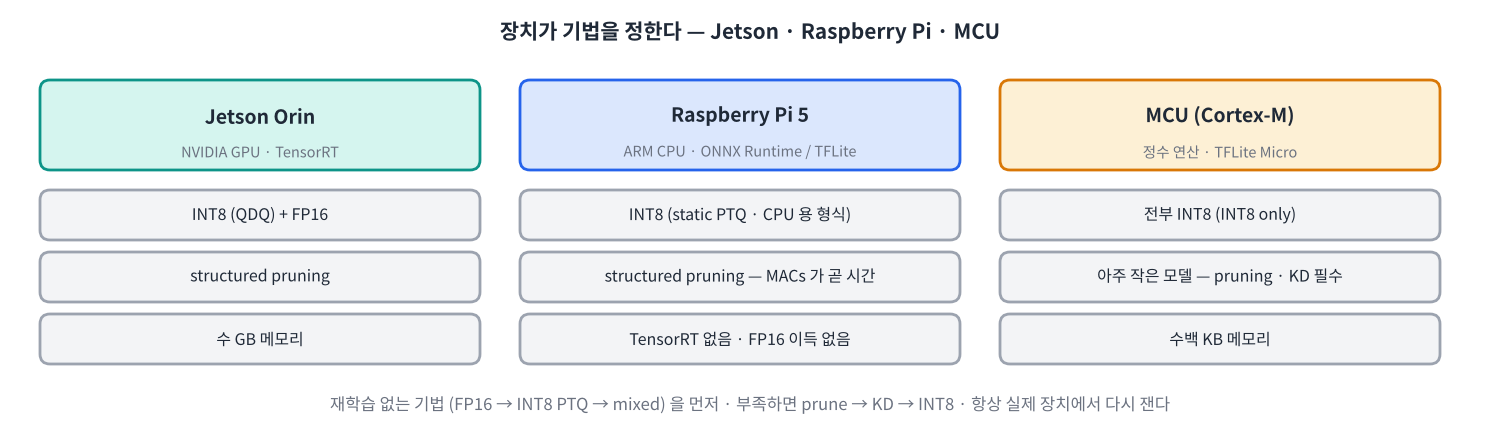

In [ ]:
#@title 🖼 그림 — 장치별 경량화 선택 — Jetson · Raspberry Pi · MCU
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day6/img/f7_decision.png", embed=True, width=860))

**✍️ 직접 구현 7-1** `qp_baseline.csv` 에 오늘의 결과 **5행** 을 추가하고 전체를 `final_df` 로 읽으세요 (열 `day, model, quant, size_kb, acc, mean_ms, p95_ms, fps_b32`, `day="Day6"`).
- 분류 2행: `model` = `rn20_p50_kd` (`quant="FP32 (prune 50% + KD)"`, 파일 `rn20_p50_kd.onnx`) · `rn20_p50_kd_int8` (`quant="INT8 (prune 50% + KD)"`, 파일 `rn20_p50_kd_int8.onnx`) — `size_kb`, `acc` = `onnx_acc`, `mean_ms` = `deploy_lat(파일, int8=…)`, 나머지 NaN.
- 침입 감지 3행: `model="yolov8n_intrusion"`, `quant` = 엔진 이름 — `size_kb` = `YOLO_FILES` 의 ONNX 크기, `acc` = **경보 일치율** (`agree_df`), `mean_ms` · `p95_ms` = 로그 `ms` 의 평균 · 95 백분위, `fps_b32` = 1000 / 평균 ms.
같은 `(day, model, quant)` 가 이미 있으면 마지막 것만 남깁니다.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 7-1 — 실행할 때마다 하나씩
show_hint("7-1", "67aE66WYIDLtlok6IGBmb3IgbmFtZSwgcGF0aCwgaW50OCBpbiBbKCJybjIwX3A1MF9rZCIsICJybjIwX3A1MF9rZC5vbm54IiwgRmFsc2UpLCAoInJuMjBfcDUwX2tkX2ludDgiLCAicm4yMF9wNTBfa2RfaW50OC5vbm54IiwgVHJ1ZSldOmAg4oCUIGAicXVhbnQiOiAoIklOVDgiIGlmIGludDggZWxzZSAiRlAzMiIpICsgIiAocHJ1bmUgNTAlICsgS0QpImAsIGAibWVhbl9tcyI6IGRlcGxveV9sYXQocGF0aCwgaW50OD1pbnQ4KWAuHuy5qOyehSDqsJDsp4AgM+2WiTogYF9hbCA9IGFncmVlX2RmLnNldF9pbmRleCgiZW5naW5lIikuYWxhcm1gIOKGkiBgZm9yIGssIGxnIGluIExPR1MuaXRlbXMoKTpgIOKAlCBgImFjYyI6IF9hbFtrXWAsIGAibWVhbl9tcyI6IGxnLm1zLm1lYW4oKWAsIGAicDk1X21zIjogbnAucGVyY2VudGlsZShsZy5tcywgOTUpYCwgYCJmcHNfYjMyIjogMTAwMCAvIGxnLm1zLm1lYW4oKWAuHuydtOyWtCDrtpnsnbTquLA6IGBiYXNlID0gcGQucmVhZF9jc3YoInFwX2Jhc2VsaW5lLmNzdiIpIGlmIG9zLnBhdGguZXhpc3RzKCJxcF9iYXNlbGluZS5jc3YiKSBlbHNlIHBkLkRhdGFGcmFtZSgpYCDihpIgYHBkLmNvbmNhdChbYmFzZSwgcGQuRGF0YUZyYW1lKHJvd3MpXSwgaWdub3JlX2luZGV4PVRydWUpLmRyb3BfZHVwbGljYXRlcyhzdWJzZXQ9WyJkYXkiLCAibW9kZWwiLCAicXVhbnQiXSwga2VlcD0ibGFzdCIpYCDihpIgYHRvX2NzdiguLi4sIGluZGV4PUZhbHNlKWAu")

In [ ]:
# ✍️ 직접 구현 7-1 — 최종 qp_baseline.csv
rows = []
# TODO: 분류 2행 (rn20_p50_kd · rn20_p50_kd_int8) + 침입 감지 3행 (yolov8n_intrusion × 엔진 3종)
# TODO: qp_baseline.csv 에 이어 붙여 저장
final_df = pd.read_csv("qp_baseline.csv")
display(final_df[final_df.day == "Day6"].round(4))

In [ ]:
_d = final_df[final_df.day == "Day6"]
assert len(_d) == 5 and set(_d.model) == {"rn20_p50_kd", "rn20_p50_kd_int8", "yolov8n_intrusion"} and set(_d[_d.model == "yolov8n_intrusion"].quant) == {"FP16", "INT8", "INT8-mixed"}
_y = _d[_d.model == "yolov8n_intrusion"].set_index("quant")
assert abs(_y.acc["FP16"] - 1) < 1e-9 and (_y.p95_ms >= _y.mean_ms * 0.9).all() and np.allclose(_y.fps_b32, 1000 / _y.mean_ms)
assert abs(_d.set_index("model").acc["rn20_p50_kd_int8"] - acc_int8_onnx) < 1e-9
print(f"✅ qp_baseline.csv — 전체 {len(final_df)}행 (Day6 5행) · 침입 감지 FPS: " + " · ".join(f"{k} {v:.1f}" for k, v in _y.fps_b32.items()))

In [ ]:
#@title 🔒 정답 보기 7-1 — 강사가 알려 준 실습 7-1 잠금 코드를 입력하세요
show_answer("7-1", (
    "Xk54mSZdVmeLAXuAwgRqvP8/ejygLwEDvgRs9pjOSfp2WldnRymLCA4GFQz9uQQEhmqGQpE1ESU6z0Qz+5twCbvo"
    "RlTXjYVVzF6mOdTO4TRAWdLC693XRBK0ghQJF5j02ifIwBPTHPi0U2+uVXiFt8zuNy/Sm6b1vr0SErKTX+QcuV7D"
    "WP5z/wjyu3AIZyfkzIc8DLYRKpuapXIFTDdrCx/3mM7EbH6dVE9vqrq2UYm7kE3Mcd/So7c1Vy+zexOK9zkgrmZ1"
    "+qMrq9v5TUT9oWT1UMUgbVWsZtBBywfskMNFH89uM13mnrKlTfbjii3Py5lyj+mNiFrUP6NEmZdWoJTO58fTiWaB"
    "rwiUjmoSpq7i2I4YHjScYqURaFmmYgfaGfPvsOcSxT5ifzADTGG392x8rGNQFCd42EHh2P835JoGQ6qfhPngwlWF"
    "kiezYoNk4HsfoOmojJQqsHNL4X1gEb5rheRPA/RjxfMDC7Tsrsb9DXRZQB7bgBmUBZgue5sZmHwZXGAhRyDAaagi"
    "hSj+JTe3WsluHFCdEb36miPKIMxyuH74ZUL4HIkNUeKf+LuDD+L0nPXqol9ARt8eiXG1BieoWp8i563dvd9KcUFY"
    "J9HDGa4X0Zg/q/0QdEZoAjnmcXTZF5+xJAd1rhms1MYO1mU2JeLGcG7Gb75+o8ZnU55AJIaFCnvsgAM07a8MUd4O"
    "haAYcK98i+XEHqlc/Vi1v7Vmr3NhTM6Ar6crGZBO+d5EdxjjJRzU7Rjv743MtoVK69jTcyUr+sQyOc4mbPS21aRI"
    "LeS5/I5tWV5cE+of5ZYa8gGD89lx0JITnRGQfpO0I3Cj8m+SbRt5FBXE3ZcSrrdJyhDkxYfj3efD/nbXiHHgJINB"
    "5+V2xqumxOWGQz7uwb6EuFgPvKdU5kx2fMuvIYpl5+9bXDOoZIjXRjg639OEUXowJ0Mz45kUR1RlCT1nIWKWV3IK"
    "uRRm+GGoSjqH8DxrJBwysnu71AeA8uI453aO1TeoLNTrNC3VseXxr9o9A2/PlZexPoBgnUByoRdzRodVqD+702J4"
    "pwqcOHI6w6EJNmXeNTd2NYKE3GckCmSbE5YH+wPwpvigNbz60QsBjzV7BhkxWe6ZbKoD3c6uV01UDcZVC0xmP5ha"
    "b65few8kzy3uhr7uZaaGO7Cu2OGS8a0g7cWEnXxYlUWYT5ekwQaw1hkORGBtdWO11HskIuThmQb3KhPcunkr0dMd"
    "p6jXw5E8MbkCQ4wF48cP2em9WSDloa0UBFFcn6Ckj8cZ9DWQARFhGHDBMNn1kYCATl6zOHxEcYLhwgjQfu/GwgPq"
    "HWKxIlaJSYvIeGK0UioRsHBHGpzJmfq/InXBMERcJk0LesMeDyvAQGCRIpsVQe4q/7YGVgrtu39XeI8421BNS0Uu"
    "t+dFBdqe1+7EN9PwMo9Zm9EiNNWrt7lFeB6SYyVQuaAUcksvMObx5zORl5IeuKHjp5SITkyNbHm6G8rYoLrRGP3g"
    "Co5xyL77ActXw2PClAj2DI2yYiiAGcOygIDoUhYochYRA9c7IuyvAeSF6Tqzq0iBxeayONyICHgx/HdKjjb9SI+z"
    "RzNhaPMtwPwVaE0HROAEph7sIhEssJAk4ee/VsfdEJNoyrjUi6M8JahciUJies7tEmjfpbm/yOafcSHGfYwqc9NZ"
    "89F8tn5TOgHFEPeh4gFaDNryHkYKk9qSWzMD2Da34rIVzZIk9ousqJS68bKfBdAt+BTLcDghQAUi5IcqD9I2uGCg"
    "bRCzm2XcrI2WJDBSVDLB2LWP2J44uV3gsSImAouLHX7ktBPM1lfuP0/tsTg4C9eBhcD1I0DcGSImlBu2GeU8pNXX"
    "u5AwfcXU2qsvQMQ6erxDLmC9iDwuQq3TZxPBwh36Gs/T9QZ5yEeMPPfG7taSrddq5LlXGUsyNWeVBs+RWizqep6U"
    "b5mXLFvZkVyR4dfR6R1LRLsq74LIl7FpMgH//KYLyOqlKARDXYLfc7mC3wZ6vXtzOgJTKB6NQ5ILry/xDJjX3VAO"
    "597/cgvv+V2Ppie+q6gETGDJALd/1A7pkmVsCb3d+MIiafvGNSxyGRwOruDNdCh6Zw=="
))


**✍️ 직접 구현 7-2** 장치 정보 딕셔너리 `dev` (`{"device", "nvidia_gpu": bool, "ram_mb": 숫자}`) 를 받아 권장 설정 `{"runtime", "precision", "pruning", "kd"}` 을 돌려주는 `recommend(dev)` 를 만드세요. 규칙:
- `runtime`: NVIDIA GPU 가 있으면 `"TensorRT"`, 없고 `ram_mb < 1` 이면 `"TFLite Micro"`, 그 밖에는 `"ONNX Runtime / TFLite"`.
- `precision`: NVIDIA GPU → `"INT8 (QDQ) + FP16"`, `ram_mb < 1` → `"INT8 only"`, 그 밖 → `"INT8 (static PTQ)"`.
- `pruning`: 항상 `"structured"` (어떤 장치에서나 빨라지는 것은 structured).
- `kd`: `ram_mb < 1024` 이면 `True` (아주 작은 모델이 필요한 장치), 아니면 `False`.
`DEVICES` 세 장치에 적용해 `decision_df` (열 `device, runtime, precision, pruning, kd`) 를 만들고 `decision_table.csv` 로 저장하세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 4개).

In [ ]:
#@title 💡 힌트 7-2 — 실행할 때마다 하나씩
show_hint("7-2", "YHRpbnkgPSBkZXZbInJhbV9tYiJdIDwgMWAg66W8IOuovOyggCDqtaztlbQg65Gh64uI64ukLh5pZiBgZGV2WyJudmlkaWFfZ3B1Il1gOiBUZW5zb3JSVCDCtyAiSU5UOCAoUURRKSArIEZQMTYiIC8gZWxpZiB0aW55OiAiVEZMaXRlIE1pY3JvIiDCtyAiSU5UOCBvbmx5IiAvIGVsc2U6ICJPTk5YIFJ1bnRpbWUgLyBURkxpdGUiIMK3ICJJTlQ4IChzdGF0aWMgUFRRKSIuHmByZXR1cm4geyJydW50aW1lIjogcnVudGltZSwgInByZWNpc2lvbiI6IHByZWNpc2lvbiwgInBydW5pbmciOiAic3RydWN0dXJlZCIsICJrZCI6IGRldlsicmFtX21iIl0gPCAxMDI0fWAuHmBkZWNpc2lvbl9kZiA9IHBkLkRhdGFGcmFtZShbeyJkZXZpY2UiOiBkWyJkZXZpY2UiXSwgKipyZWNvbW1lbmQoZCl9IGZvciBkIGluIERFVklDRVNdKWAg4oaSIGB0b19jc3YoImRlY2lzaW9uX3RhYmxlLmNzdiIsIGluZGV4PUZhbHNlKWAu")

In [ ]:
# ✍️ 직접 구현 7-2 — 경량화 결정표
DEVICES = [{"device": "Jetson Orin Nano", "nvidia_gpu": True, "ram_mb": 8192},
           {"device": "Raspberry Pi 5", "nvidia_gpu": False, "ram_mb": 8192},
           {"device": "MCU (Cortex-M7)", "nvidia_gpu": False, "ram_mb": 0.5}]

def recommend(dev):
    # TODO: {"runtime": ..., "precision": ..., "pruning": ..., "kd": ...}
    pass

decision_df = None   # TODO: 열 device, runtime, precision, pruning, kd → decision_table.csv
display(decision_df)

In [ ]:
assert decision_df.runtime.tolist() == ["TensorRT", "ONNX Runtime / TFLite", "TFLite Micro"]
assert decision_df.precision.tolist() == ["INT8 (QDQ) + FP16", "INT8 (static PTQ)", "INT8 only"]
assert (decision_df.pruning == "structured").all() and decision_df.kd.tolist() == [False, False, True] and os.path.exists("decision_table.csv")
assert recommend({"device": "Jetson Nano 2GB", "nvidia_gpu": True, "ram_mb": 512}) == {"runtime": "TensorRT", "precision": "INT8 (QDQ) + FP16", "pruning": "structured", "kd": True}
print("✅ 경량화 결정표 — " + " | ".join(f"{r.device}: {r.runtime} · {r.precision}" for r in decision_df.itertuples()))

In [ ]:
#@title 🔒 정답 보기 7-2 — 강사가 알려 준 실습 7-2 잠금 코드를 입력하세요
show_answer("7-2", (
    "sxapoJZfBkPOSYgwEZMxoBGUoEUlaemN8y+5G4M/xeZLMehq2Lhk8nvwBmtXAWNghk4vgXOWMiUgxV3/8yizqXP/"
    "OS+ROy11cvBAvGWLE5i2OR7Z8xFMLkG7kEK87ECOvzSdggOjyFkwnXsEBATUDG2rDIUgjFUWiwVSD6JJilRs6/E9"
    "fWBwDOPcA1lcalhkz3OsSKk8iCLbA6iJeP0rA8Ktj3+5BpAkscWPf6L4NtGT6pYeQjjI7IrDvwX4Nmuy6dSHUDVC"
    "e//xP780k34yVE0joKWp0YYLqWQ1slNxm4Oj07BCi8/HhNcTlLd3z7yfJcjukR+VHB0cae2ug8Zfi3oLMFqgP9fH"
    "FoVIBiejAbNUPRKlbabjodf9iIFODe0fdn0JwB0gMAzavnFNVffL/319M3AD4hMlasLr+ibS+yzrT/qpFmv36PI5"
    "pN/L/4FrlVDLAYqbttq3szIlFtRckHCSgpAN4EnCozxBFhovKpEBgLrtjb/IMiYlNzjN12A8C+FYHWNi0umagMHM"
    "Axy2TGbw3/4DSASPfvajVWd4QLAKVLqcukORkW7gIIMup5sZQe7LBFrRzPJHYZz+nzEF4yBmlISXApDJtOqy7LuX"
    "C9DJf6YixTKjNq4U//SX50bI777w74slBJE1vFcbM07JAcPyT40l+Wd2CtOKBlAQhmeA3ZY9egK3i0pD4DBxmA47"
    "OpJFOx0m3bs4weWonCjHWyhRmYAZX0HnQId9TiWIEo68EyH3RwRoCCmWrdHRPzvzmRZJ9kflrN2h7S/fALnD1kiS"
    "J3q6VYg7Ij3Nq+/MrBI8BCmklox0cA5HDF4KpNKox+xchHaHw8aUeWj3aRN8W+ih7I+l0t/1G6U+ysOGRGtjJm/g"
    "KNRi0bVnxxYkd/nHXI0bsIzSYSOKkyjJHMWV+DUHJ0fTA1JC1dTNAcEiB1Vpjo1ZCx5CQEoBIaWVECyXfV7bHwV+"
    "11N8Pp6oRtcooig1yzdBxoUiccqWZD2gzCvL4wXa85YI9IKaoMcoXPZnlxxGJtOBZXgCVwf5ivCVyXSnvI6g8JUg"
    "pxHODx19pG3HAxg7Ln36HgzlZLXrSMjHdRF+WhceTrCMANnXODH20zyZkIGYbEMdjsYOU1H45L2cNR+IsRsVw0kh"
    "LvwYq38v3nftLRrAFbEwC7RZpTuJXZLSJpvcT2VzACvYe9CyXrnsQcnFZua/TLc4oOP9qWC9blKs8he7S9PqtsPc"
    "+iXA3z6pjTv5RvCndpsksnn0cwcS/u2gMBKC7ndyjKZn6ySYPtL6TBA344dcuM+d7x0bP/9BYfq31WeqLViJis13"
    "iJr09j0X6RjyAE5hJIs7PQru5zYYZg3BPMqfIa0ammkVFmibAZ7kYvSrM6qBbWr3fvTdM/3OXXWAoddLS+aZmHao"
    "PpnKzliYVpZCZIX8iBkN/Qwk8c151O1JNptECSO4Xj57L9CERSsRFjbpjBnZ+QT/4NDlVgmAEp0pYeixBRCAHqBm"
    "oC1u0MGhOCiwaxA+hu+Cl3MJPpaxIn0YZ6mn+HlxbT0hzxeDsxVocvpSS3xWZy1sxp2SKPgCCQ4tF17TREsvfguk"
    "M1txcuwAYCRDFOz/Y2G+WCcWYxfNqVBj8B3TIQ3Cmhp46sSyigtLdRqaYZw588V2aL5AKl2B1UmWDMn57cuzKRrZ"
    "P6XZRRAjJpZ94w0R6ZPLI4cxI6Jl4jT2r0tNEHT1+uomzF23j7Sl+/c="
))


#### 📌 7교시 정리

- 결과는 한 표 (`qp_baseline.csv`) 에 — 크기 · 지연 · p95 · FPS · 정확도 (또는 일치율).
- 재학습 없는 기법 (FP16 → INT8 PTQ → mixed) 을 먼저, 부족하면 prune → KD → INT8.
- 장치가 기법을 정한다: Jetson = TensorRT INT8 QDQ, Raspberry Pi = CPU 용 INT8 + structured pruning, MCU = 전부 INT8 + 아주 작은 모델.

## 8교시 — 미니 프로젝트: 평가 대비 예제 2문항 (쉬움 · 중간)

내일 (11/24) **파트2 평가** (ONNX·TensorRT + Quantization·Pruning) 의 실습 문항과 같은 수준의 예제 2문항을 **혼자 힘으로** 풉니다. 오늘까지 만든 함수 (데이터 셀의 `make_trt_int8` · `prune_channels` · `finetune` · `deploy_lat` · 오늘의 `train_kd`) 를 써도 됩니다.

| 과제 | 수준 | 내용 | 배점 |
|---|---|---|---|
| 1 | 쉬움 | ONNX 모델 **static PTQ** 후 정확도 · 지연 · 크기 비교 표 `ptq_df` | 30 |
| 2 | 중간 | **structured pruning 30% + 학습 3 epoch** 후 결과표 `prune_df` | 40 |
| 3 | — | 결과 저장 `eval_practice.csv` · 요약 `answer` | 20 |
| 4 | — | 결론 쓰기 (마크다운) | 10 |

**평가 범위 (파트2)**

| 과목 | 필답에서 묻는 것 (예) | 실습에서 하는 것 (예) |
|---|---|---|
| ONNX·TensorRT | ONNX 그래프 · opset · dynamic axes · ORT provider · 엔진 빌드 · FP16 | ONNX export → ORT 추론 → 지연 측정 · 성능표 |
| Quantization·Pruning | scale · zero-point 계산 · PTQ / QAT · calibration · QDQ · mixed precision · unstructured vs structured · KD | **static PTQ 후 비교 (쉬움)** · **structured pruning + fine-tuning 결과표 (중간)** |

> 제출은 **소스 기준 · 기능별 부분 점수** 입니다 — 끝까지 못 해도 만든 곳까지 실행되는 상태로 제출하세요. 미니 프로젝트에는 **정답 보기 셀이 없습니다.** 채점 셀을 실행하면 자동 채점 점수와 **정답 열람 기록**이 나옵니다 (과제 4 는 강사 채점).

> 🎬 **애니메이션** [D6-8 평가 대비 정리](https://imguru-mooc.github.io/AI_CAMPUS/QP-day6/animation.html#d6-8)
> 애니메이션은 **이 교시의 노트북 순서 그대로**입니다 — 단계마다 먼저 **예측**을 고르고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

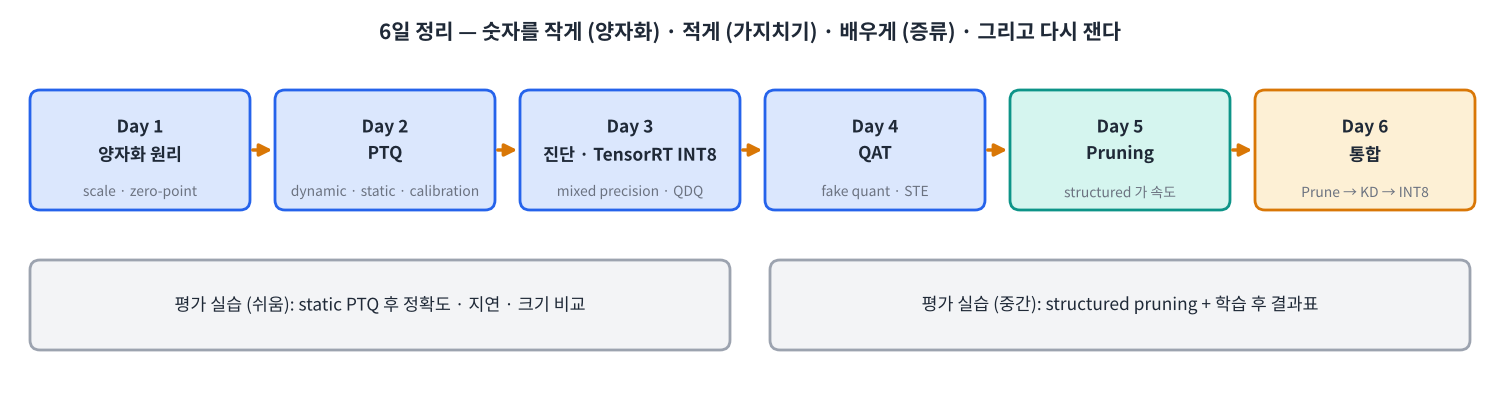

In [ ]:
#@title 🖼 그림 — 6일 정리 — 양자화 · 가지치기 · 증류 · 배포 판단
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day6/img/f8_review.png", embed=True, width=860))

**과제 1 (30점 · 쉬움)** 원본 `rn20` 을 배치 1 ONNX `eval_fp32.onnx` 로 내보내고 (`export_b1`), **static PTQ** (`make_trt_int8` — QDQ · S8 대칭 · 보정 500장) 로 `eval_int8.onnx` 를 만드세요. 두 모델의 크기 (KB) · 정확도 (`onnx_acc`) · 지연 (`deploy_lat(파일, int8=…)`) 을 `ptq_df` (열 `model, size_kb, acc, latency_ms` — 행 `FP32`, `INT8`) 로 만드세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 2개).

In [ ]:
#@title 💡 힌트 8-1 — 실행할 때마다 하나씩
show_hint("8-1", "YGV4cG9ydF9iMShjb3B5LmRlZXBjb3B5KHJuMjApLCAiZXZhbF9mcDMyLm9ubngiKWAg4oaSIGBtYWtlX3RydF9pbnQ4KCJldmFsX2ZwMzIub25ueCIsICJldmFsX2ludDgub25ueCIpYC4e7ZaJOiBgeyJtb2RlbCI6IG5hbWUsICJzaXplX2tiIjogc2l6ZV9rYihwKSwgImFjYyI6IG9ubnhfYWNjKHApLCAibGF0ZW5jeV9tcyI6IGRlcGxveV9sYXQocCwgaW50OD1pOCl9YCDigJQgSU5UOCDsnYAgYGludDg9VHJ1ZWAu")

In [ ]:
# ✍️ 과제 1 (쉬움) — static PTQ 후 비교
# TODO: eval_fp32.onnx · eval_int8.onnx
ptq_df = None   # TODO: 열 model, size_kb, acc, latency_ms — 행 FP32, INT8
display(ptq_df.round(4)); print(trt_check("eval_int8.onnx"))

**과제 2 (40점 · 중간)** `rn20` 의 채널을 **30%** 자른 `p30` 을 만들고 (`prune_channels`), 그 복사본 `p30_tuned` 를 **3 epoch 학습** (`finetune` 또는 `train_kd` — 선택) 하세요. 원본 · 가지치기 직후 · 학습 뒤 세 모델의 MACs (M) · params · 정확도 · 지연 (ONNX 로 내보내 `deploy_lat`) 을 `prune_df` (열 `model, macs_m, params, acc, latency_ms` — 행 `FP32`, `pruned 30%`, `pruned 30% + tuned`) 로 만드세요. 학습에 쓴 방법을 `method` (`"finetune"` 또는 `"kd"`) 에 적으세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 2개).

In [ ]:
#@title 💡 힌트 8-2 — 실행할 때마다 하나씩
show_hint("8-2", "YHAzMCA9IHBydW5lX2NoYW5uZWxzKHJuMjAsIDAuMylgIMK3IGBwMzBfdHVuZWQgPSBjb3B5LmRlZXBjb3B5KHAzMClgIOKGkiBgZmluZXR1bmUocDMwX3R1bmVkKWAg65iQ64qUIGB0cmFpbl9rZChwMzBfdHVuZWQsIHJuMjApYC4e66qo642466eI64ukIGBleHBvcnRfYjEoY29weS5kZWVwY29weShtKSwg7YyM7J28KWAg66GcIOuCtOuztOuCuCDrkqQgYGRlcGxveV9sYXQo7YyM7J28KWAgwrcgYG1hY3NfbShtKWAgwrcgYG5fcGFyYW1zKG0pYCDCtyBgYWNjX3RvcmNoKG0pYC4=")

In [ ]:
# ✍️ 과제 2 (중간) — structured pruning 30% + 학습 3 epoch
p30 = None          # TODO
p30_tuned = None    # TODO: p30 복사본을 3 epoch 학습
method = None       # TODO: "finetune" 또는 "kd"
prune_df = None     # TODO: 열 model, macs_m, params, acc, latency_ms — 행 FP32, pruned 30%, pruned 30% + tuned
display(prune_df.round(4))

**과제 3 (20점)** (1) `ptq_df` 와 `prune_df` 를 위아래로 붙여 (`task` 열 추가: `"ptq"` · `"prune"`) `eval_practice.csv` 로 저장하세요. (2) 요약 `answer` 를 만드세요: `{"ptq_size_x": FP32 크기 / INT8 크기, "ptq_acc_drop_pp": (FP32 − INT8 정확도) × 100, "prune_macs_x": FP32 MACs / 가지치기 MACs, "prune_acc_drop_pp": (FP32 − 학습 뒤 정확도) × 100, "pass_3pp": 학습 뒤 정확도가 FP32_ACC − 0.03 이상인가}`.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 2개).

In [ ]:
#@title 💡 힌트 8-3 — 실행할 때마다 하나씩
show_hint("8-3", "YHBkLmNvbmNhdChbcHRxX2RmLmFzc2lnbih0YXNrPSJwdHEiKSwgcHJ1bmVfZGYuYXNzaWduKHRhc2s9InBydW5lIildLCBpZ25vcmVfaW5kZXg9VHJ1ZSkudG9fY3N2KCJldmFsX3ByYWN0aWNlLmNzdiIsIGluZGV4PUZhbHNlKWAuHmBhbnN3ZXJgIOydmCBgcGFzc18zcHBgIOuKlCBgYm9vbChwcnVuZV9kZi5hY2NbMl0gPj0gRlAzMl9BQ0MgLSAwLjAzKWAu")

In [ ]:
# ✍️ 과제 3 — 저장 · 요약
# TODO: eval_practice.csv
answer = None   # TODO: {"ptq_size_x", "ptq_acc_drop_pp", "prune_macs_x", "prune_acc_drop_pp", "pass_3pp"}
print({k: (round(float(v), 3) if not isinstance(v, bool) else v) for k, v in answer.items()})

### 과제 4 — 결론 (10점)

아래 셀에 답을 쓰세요 (각 2~3줄).

1. 과제 1 의 표로 "INT8 PTQ 를 배포해도 되는가" 를 숫자와 함께 판단하세요. CPU 에서 QDQ INT8 이 FP32 보다 느리게 나왔다면 왜일까요?
2. 과제 2 의 30% 모델은 Day 5 의 기준 (FP32 대비 3%p 이내) 을 만족하나요? 만족하지 못한다면 무엇을 바꾸겠습니까?
3. 오늘의 파이프라인 순서 (Prune → KD → INT8) 에서 양자화가 마지막인 이유를 실습 3-2 의 오류와 연결해 설명하세요.
4. 침입 감지에서 INT8 엔진을 FP16 대신 배포하려면 어떤 수치를 확인해야 할까요? (6 · 7교시)

✍️ *여기에 답을 쓰세요.*

### 채점 셀

In [ ]:
score = 0
try:
    assert ptq_df.model.tolist() == ["FP32", "INT8"] and list(ptq_df.columns) == ["model", "size_kb", "acc", "latency_ms"]
    assert trt_check("eval_int8.onnx")["ok"] and abs(ptq_df.acc[0] - FP32_ACC) < 0.003 and ptq_df.acc[1] > FP32_ACC - 0.02
    assert abs(ptq_df.size_kb[1] - size_kb("eval_int8.onnx")) < 1e-6 and (ptq_df.latency_ms > 0).all()
    score += 30; print("✅ 과제 1  +30")
except Exception as e: print("❌ 과제 1", repr(e))
try:
    assert prune_df.model.tolist() == ["FP32", "pruned 30%", "pruned 30% + tuned"] and list(prune_df.columns) == ["model", "macs_m", "params", "acc", "latency_ms"]
    assert 0.35 < prune_df.macs_m[1] / prune_df.macs_m[0] < 0.6 and abs(prune_df.macs_m[1] - prune_df.macs_m[2]) < 1e-6 and prune_df.params[1] < prune_df.params[0]
    assert prune_df.acc[2] > prune_df.acc[1] + 0.2 and prune_df.acc[2] > 0.7 and method in ("finetune", "kd") and abs(prune_df.acc[2] - acc_torch(p30_tuned)) < 1e-9
    score += 40; print("✅ 과제 2  +40")
except Exception as e: print("❌ 과제 2", repr(e))
try:
    c_ = pd.read_csv("eval_practice.csv")
    assert len(c_) == 5 and c_.task.tolist() == ["ptq"] * 2 + ["prune"] * 3
    assert abs(answer["ptq_size_x"] - ptq_df.size_kb[0] / ptq_df.size_kb[1]) < 1e-6 and abs(answer["ptq_acc_drop_pp"] - (ptq_df.acc[0] - ptq_df.acc[1]) * 100) < 1e-6
    assert abs(answer["prune_macs_x"] - prune_df.macs_m[0] / prune_df.macs_m[2]) < 1e-6 and abs(answer["prune_acc_drop_pp"] - (prune_df.acc[0] - prune_df.acc[2]) * 100) < 1e-6
    assert answer["pass_3pp"] == bool(prune_df.acc[2] >= FP32_ACC - 0.03)
    score += 20; print("✅ 과제 3  +20")
except Exception as e: print("❌ 과제 3", repr(e))
print(f"\n자동 채점 {score} / 90  (+ 과제 4 강사 채점 10점) | 장치: {DEV} · 측정: {BACKEND}")
seen = [l.split("\t")[0] for l in open(".qp_answer_log")] if os.path.exists(".qp_answer_log") else []
seen = list(dict.fromkeys(seen))
print(f"정답 열람 {len(seen)}개" + (f" — {', '.join(seen)}" if seen else " — 없음 👍"))

#### 📌 8교시 정리

- 평가 실습은 **표 + 수치로 쓴 한 줄 결론** 까지가 한 세트.
- 쉬움: static PTQ → 크기 · 정확도 · 지연 비교. 중간: structured pruning → 학습 → MACs · 정확도 · 지연 결과표.
- 끝까지 못 해도 **실행되는 곳까지** 제출 — 기능별 부분 점수.

## 6일 정리

| Day | 주제 | 한 줄 |
|---|---|---|
| 1 | 양자화 원리 | scale · zero-point 로 FP32 ↔ INT8 · 오차는 clipping 과 rounding |
| 2 | PTQ (ONNX Runtime) | dynamic · static · calibration — 8비트는 대부분 PTQ 로 충분 |
| 3 | 오차 진단 · TensorRT INT8 | 범인 layer 찾기 → mixed precision · QDQ ONNX → 엔진 |
| 4 | QAT | fake quant + STE — PTQ 손실이 클 때 (저비트) 만 |
| 5 | Pruning | unstructured 는 0 만, **structured 가 속도** · fine-tuning 과 한 세트 |
| 6 | 통합 | Prune → KD → INT8 · 파이프라인에서 다시 재기 · 장치가 기법을 정한다 |

### 셀프 체크

- [ ] soft target · temperature 를 설명하고 KD loss 를 구현했다
- [ ] 가지치기 모델을 fine-tuning 과 KD 로 같은 예산에서 비교했다
- [ ] Prune → KD → INT8 순서의 이유를 오류로 확인하고 `compress.py` 를 만들었다
- [ ] YOLOv8n 을 배포 영상으로 보정해 INT8 · INT8-mixed 를 만들고 침입 감지 엔진을 교체했다
- [ ] 프레임 시간을 네 단계로 나누고 FP16 기준 일치율 · 이벤트 재현율을 쟀다
- [ ] 최종 `qp_baseline.csv` 와 경량화 결정표를 만들었다
- [ ] 평가 대비 예제 2문항을 표와 결론까지 풀었다

### 다음 일정

- **11/24 (화)** 파트2 (ONNX·TensorRT · Quantization·Pruning) 필답 + 실습 평가.
- **12월 [프로젝트] 현장 안전 모니터링** — 오늘의 `compress.py` · INT8 침입 감지 파이프라인 · `qp_baseline.csv` · 경량화 결정표를 배포 기준으로 씁니다.

> 📦 `compress.py` · `qp_baseline.csv` · `decision_table.csv` · `intrusion_int8.mp4` · `events_*.csv` 를 내 컴퓨터 (또는 Drive) 에 내려받아 두세요.

## 📝 Day 6 복습 퀴즈 — 수업이 끝난 뒤

오늘 배운 1~8교시 내용을 **24문항**으로 점검합니다. 9가지 유형이 섞여 있습니다.

👉 **[Day 6 복습 퀴즈 열기](https://imguru-mooc.github.io/AI_CAMPUS/QP-day6/review_quiz.html)**

1. 이름을 입력하고 24문항을 모두 풉니다.
2. **채점하기** → 정오와 해설이 나타납니다. 채점 후에는 답이 잠깁니다.
3. **제출 (오답 정리)** → 점수 · 결과 코드 · 오답 정리를 **텍스트 복사** 또는 캡처로 강사가 안내한 곳에 제출합니다.